# <a href="https://thetahat.ru/courses/ad">Введение в анализ данных</a>
## Домашнее задание 6. Компьютерное зрение & генеративные модели


**Правила, <font color="red">прочитайте внимательно</font>:**

1. Общее

     * Выполненную работу **в формате `ipynb`** нужно отправить по ссылке "Сдача ДЗ" на <a href="https://thetahat.ru/courses/ad"><b>странице курса</b></a>. **Работы, присланные иным способом, не принимаются.** Дедлайны указаны в боте и на сайте, они являются строгими.
     
     * Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><b>руководство по оформлению ДЗ</b></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.
     
     * Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><b>правила использования ИИ-инструментов</b></a> при решении домашнего задания.
     
     * Выполнять задание необходимо полностью самостоятельно. **При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф -3 скор-балла к итоговой оценке.**
     
     * Решение теоретических задач оформляйте в markdown-ячейках формате $\LaTeX$. При решении можно использовать ИИ-инструменты только для оформления написанного самостоятельно решения. Например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.
     
     * Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/"><img src="https://miptstats.github.io/theta_grader_small.png" style="display: inline; vertical-align: middle;"></a> **ThetaGrader**. Результат проверки валидируется и исправляется человеком, после чего комментарии отправляются студентам.
     </br>

2. Правила заполнения ноутбука

     * Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.
     * Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены `<...>`.
     * Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках.
     * Условия <font color="red"><b>запрещается модифицировать</b></font>.
     * При нарушении данных правил работа может получить 0 баллов.
</br>


**Баллы за задание:**

* Задача 1 &mdash; 120 баллов
* Задача 2 &mdash; 80 баллов
* Задача 3 &mdash; 30 баллов

In [1]:
# Bot check

# HW_ID: fpmi_ad6
# Бот проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так бот проверит, что ты отправляешь финальную версию, а не промежуточную.
# Никакие значения в этой ячейке не влияют на факт сдачи работы.

In [2]:
# При необходимости установите библиотеки, например, раскомментируйте строку ниже
!pip install torchinfo
!pip install opencv-python
!git clone https://github.com/nazianafis/Neural-Style-Transfer
!pip install diffusers transformers accelerate

Cloning into 'Neural-Style-Transfer'...
remote: Enumerating objects: 379, done.
remote: Counting objects: 100% (154/154), done.
remote: Compressing objects: 100% (119/119), done.
remote: Total 379 (delta 72), reused 105 (delta 34), pack-reused 225 (from 1)
Receiving objects: 100% (379/379), 92.21 MiB | 23.78 MiB/s, done.
Resolving deltas: 100% (143/143), done.


### 📌 Примечание

В ходе доработки решения были внесены следующие исправления:

**Задача 1:**
- **Эксперимент 1:** доработан график, использованы разные цвета (для моделей) и стили линий (для train и val).

- Изначально на графике это было учтено, но цвета разных моделей были базовые для графика.

- Добавлено 2 приближенных графика.

- **Эксперимент 2:** доработан график, использованы разные цвета (для моделей) и стили линий (для train и val).

- Добавлено 2 приближенных графика.

- **Замечание:** ▫️ 2 линии, отображающие точность моделей, трудно различить, поскольку они почти полностью сливаются. **Мой ответ:** проблема в том, что модели сходятся почти к одинаковым значениям, поэтому линии сливаются в конце, по оформлению я постарась сделать всё что смогла. Добавлено: `linewidth` и `alpha`.

- **Исправлено:** ▫️ Эксп. 2: Неинформативный график из-за большого масштаба.
- Задала масштаб по оси Y.

- **Исправлено:** ▫️ Эксп. 2: Не выведены числовые значения accuracy на тесте, а на графике отличия плохо видно.

- Поскольку на графике точности в эксперименте 2 модели почти неразличимы, дополнительно выведены итоговые числовые значения val_accuracy для каждой модели.
- **Исправлено:** ▫️ В выводе упущены результаты наблюдей по разным конфигурациям сверточной сети из экспериментов 1 и 2.

- **Исправлено:** ▫️ Инд. комм. В итоговом анализе в ячейке 34 не выведено численное значение общей точности из-за отсутствия префикса 'f' в f-строке, что скрыло результат вычисления.

- **Исправлено:** ▫️ Инд. комм. В эксперименте 2 требовалось варьировать размеры ядер всех сверточных слоев, однако изменения были применены только к первому слою, а в остальных слоях размер ядра остался фиксированным.

**Задача 2:**
- **Исправлено замечание:** Нет ответа на вопрос: "Какую функцию они могут нести?" или он не корректен. **Добавлен отдельный ответ на вопрос**.

- **Исправлено:** Инд. комм. В выводе по фильтрам первого сверточного слоя вы ошибочно указываете, что визуализация получена с помощью максимизации активации, хотя на самом деле это прямая визуализация весов (фильтров) слоя. **Вывод по фильтрам первого сверточного слоя**.

- **Исправлено:** ▫️ На визулизациях не спрослеживаются паттерны.
- Уменьшила learning_rate с 1.0 до 0.1 — более плавная и стабильная оптимизация.
- Добавила периодическую нормализацию каждые 100 шагов внутри visualize_filter.

- **Исправлено:** ▫️ Не для всех фильтров в слое есть визуализации.
- В задаче по визуализации активирующих изображений для каждого сверточного слоя изначально я показала результаты только для 8 фильтров из 32. **Это замечание исправлено**.


**Задача 3:**
- Исправлено: ▫️ Инд. комм. Использование `os.chdir` с абсолютным путём (ячейка 68) делает код непереносимым и зависимым от вашей локальной файловой системы.

- Исправлено: ▫️ Инд. комм. Выводы ячеек 75 и 76 неполны: в ячейке 75 не отображается успешная загрузка модели, а в 76 отсутствует лог генерации, хотя итоговые изображения присутствуют.


In [3]:
import warnings
from typing import Union

import os
from pathlib import Path

import time
from collections import defaultdict

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
from diffusers import AutoPipelineForText2Image
from torchinfo import summary

from google.colab import files
import zipfile

sns.set(font_scale=1, style="darkgrid", palette="Set2")
warnings.simplefilter("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


Перед выполнением задания обязательно посмотрите <a href="https://thetahat.ru/files/ad/main/7/CV_intro no_pause.pdf" target="_blank">презентацию</a> и <a href="https://thetahat.ru/courses/ad/main/7/cv_classification" target="_blank">ноутбук</a> про сверточные сети и классификацию, а так же <a href="https://thetahat.ru/files/ad/main/7/CV_complex_no_pause.pdf" target="_blank">презентацию</a> и <a href="https://thetahat.ru/courses/ad/main/7/cv_complex_examples" target="_blank">ноутбук</a> про перенос стиля и генеративные сети.

&#x2757; **Весь код работы с библиотекой PyTorch необходимо написать самостоятельно, без использования ИИ-инструментов.** Но можно использовать код из ноутбуков, рассказанных на занятии. Можно использовать ИИ-инструменты для написания технического кода (например, построение графиков), оформления ранее написанного кода и в качестве справки. Выводы необходимо делать самостоятельно.

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 1**
1. ссылка
    - для чего использована
    - для чего использована
2. ссылка
    - для чего использована

**Задача 2**
1. ссылка
    - для чего использована


---
### Задача 1. Классификация MNIST


В данной задаче вам нужно провести сравнительный анализ сверточных нейросетей с различными параметрами на датасета рукописных цифр MNIST. С этим датасетом вы уже познакомились в <a href="https://thetahat.ru/courses/ad/main/6/vvad_hw5">предыдущем задании</a>. Классификация в MNIST значительно проще, чем в CIFAR, рассмотренном на <a href="https://thetahat.ru/courses/ad/main/7/cv_classification" target="_blank">занятии</a>, поэтому ваша задача — достичь **на валидации** хотя бы одной из моделей точности 97%. Вы можете свободно использовать код с занятия.

> Использования слоев с семинара (свертка, pooling) более чем достаточно для достижения 97% точности на тесте. Также не делайте сеть глубокой.

> Тестируйте работоспособность кода на CPU с небольшим количеством итераций. Если все работает, и хочется ускорить процесс, переходите на GPU.

Следуйте указаниям ниже.

**1.** Загрузим датаcет из `torchvision.datasets`.

In [4]:
# Данные для обучения
train_dataset = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transforms.ToTensor()
)
# Данные для тестирования
val_dataset = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transforms.ToTensor()
)
# Классы объектов в датасете
num_classes = 10
classes_list = [str(i) for i in range(num_classes)]

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 624kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.54MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.52MB/s]


Создайте генераторы батчей.

In [5]:
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [6]:
# Функция для вычисления точности по логитам
def accuracy_from_logits(logits, labels):
    preds = logits.argmax(dim=1)
    return (preds == labels).float().mean().item()

**2.** Создайте хотя бы 5 сверточных нейросетей с разным количеством линейных и сверточных слоев. Должен присутствовать хотя бы 1 сверточный слой и хотя бы 1 линейный слой. Для каждой посмотрите количество параметров с помощью `torchinfo.summary`. Никакие специальные слои, которые мы не изучали, использовать не нужно.

In [7]:
# 1 свёртка, 1 линейный
model_1 = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 14 * 14, 10)
)

# 1 свёртка, 2 линейных
model_2 = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 14 * 14, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)

# 2 свёртки, 1 линейный
model_3 = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(64 * 7 * 7, 10)
)

# 2 свёртки, 2 линейных
model_4 = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(64 * 7 * 7, 192),
    nn.ReLU(),
    nn.Linear(192, 10)
)

# 3 свёртки
model_5 = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=5, stride=2, padding=2),
    nn.ReLU(),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(128 * 3 * 3, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 10)
)

models_dict = {
    "model_1": model_1,
    "model_2": model_2,
    "model_3": model_3,
    "model_4": model_4,
    "model_5": model_5,
}

In [8]:
for model_name, model in models_dict.items():
    print(f"\n{model_name}:")
    print(summary(model, input_size=(1, 1, 28, 28), device=device))


model_1:
Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 10]                   --
├─Conv2d: 1-1                            [1, 32, 28, 28]           320
├─ReLU: 1-2                              [1, 32, 28, 28]           --
├─MaxPool2d: 1-3                         [1, 32, 14, 14]           --
├─Flatten: 1-4                           [1, 6272]                 --
├─Linear: 1-5                            [1, 10]                   62,730
Total params: 63,050
Trainable params: 63,050
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.31
Input size (MB): 0.00
Forward/backward pass size (MB): 0.20
Params size (MB): 0.25
Estimated Total Size (MB): 0.46

model_2:
Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 10]                   --
├─Conv2d: 1-1                            [1, 32, 28, 28]           320
├─ReLU: 1-2                            

Обучите сети, используя функцию потерь `nn.CrossEntropyLoss` и оптимизатор `torch.optim.SGD` с дефолтными параметрами.

In [9]:
def evaluate_model(model, batch_gen, criterion, device="cpu"):
    """Оценивает модель: возвращает средний loss и accuracy."""
    model.eval()
    total_loss = 0.0
    total_acc = 0.0
    total_size = 0

    with torch.no_grad():
        for images, labels in batch_gen:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)
            acc = accuracy_from_logits(logits, labels)

            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            total_acc += acc * batch_size
            total_size += batch_size

    return total_loss / total_size, total_acc / total_size


def train_model(model, train_loader, val_loader, num_epochs=40, device="cpu"):
    """Обучает модель, возвращает модель, историю метрик и время обучения."""
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

    history = defaultdict(list)
    start_time = time.time()

    for epoch in range(1, num_epochs + 1):
        # Обучение
        model.train()
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

        # Валидация
        train_loss, train_acc = evaluate_model(model, train_loader, criterion, device)
        val_loss, val_acc = evaluate_model(model, val_loader, criterion, device)

        # Сохраняем историю
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch}: train_loss={train_loss:.4f}, train_acc={train_acc:.4f}, "
              f"val_loss={val_loss:.4f}, val_acc={val_acc:.4f}")

    elapsed_time = time.time() - start_time
    return model, history, elapsed_time

In [10]:
# Обучение всех моделей
results = {}

for model_name, model in models_dict.items():
    print(f"\n{'='*60}")
    print(f"Начало обучения {model_name}")
    print('='*60)

    trained_model, history, elapsed_time = train_model(
        model,
        train_loader,
        val_loader,
        num_epochs=20,
        device=device
    )

    results[model_name] = {
        "model": trained_model,
        "history": history,
        "time": elapsed_time
    }

    final_val_acc = history["val_acc"][-1]
    print(f"{model_name} обучена за {elapsed_time:.2f} сек")
    print(f"Итоговая val_acc: {final_val_acc:.4f} ({final_val_acc*100:.2f}%)")
    print('='*60)


Начало обучения model_1
Epoch 1: train_loss=0.3329, train_acc=0.9039, val_loss=0.3159, val_acc=0.9103
Epoch 2: train_loss=0.2998, train_acc=0.9116, val_loss=0.2894, val_acc=0.9166
Epoch 3: train_loss=0.2723, train_acc=0.9230, val_loss=0.2630, val_acc=0.9244
Epoch 4: train_loss=0.2668, train_acc=0.9239, val_loss=0.2584, val_acc=0.9282
Epoch 5: train_loss=0.2373, train_acc=0.9324, val_loss=0.2298, val_acc=0.9343
Epoch 6: train_loss=0.2368, train_acc=0.9314, val_loss=0.2356, val_acc=0.9320
Epoch 7: train_loss=0.2143, train_acc=0.9404, val_loss=0.2069, val_acc=0.9427
Epoch 8: train_loss=0.1893, train_acc=0.9476, val_loss=0.1856, val_acc=0.9478
Epoch 9: train_loss=0.1822, train_acc=0.9488, val_loss=0.1778, val_acc=0.9507
Epoch 10: train_loss=0.1685, train_acc=0.9546, val_loss=0.1659, val_acc=0.9530
Epoch 11: train_loss=0.1548, train_acc=0.9577, val_loss=0.1521, val_acc=0.9593
Epoch 12: train_loss=0.1438, train_acc=0.9614, val_loss=0.1436, val_acc=0.9599
Epoch 13: train_loss=0.1343, train_a

Постройте график лосса и график accuracy, где сравниваются все модели (на train и на val). Нужная функция есть в семинаре.

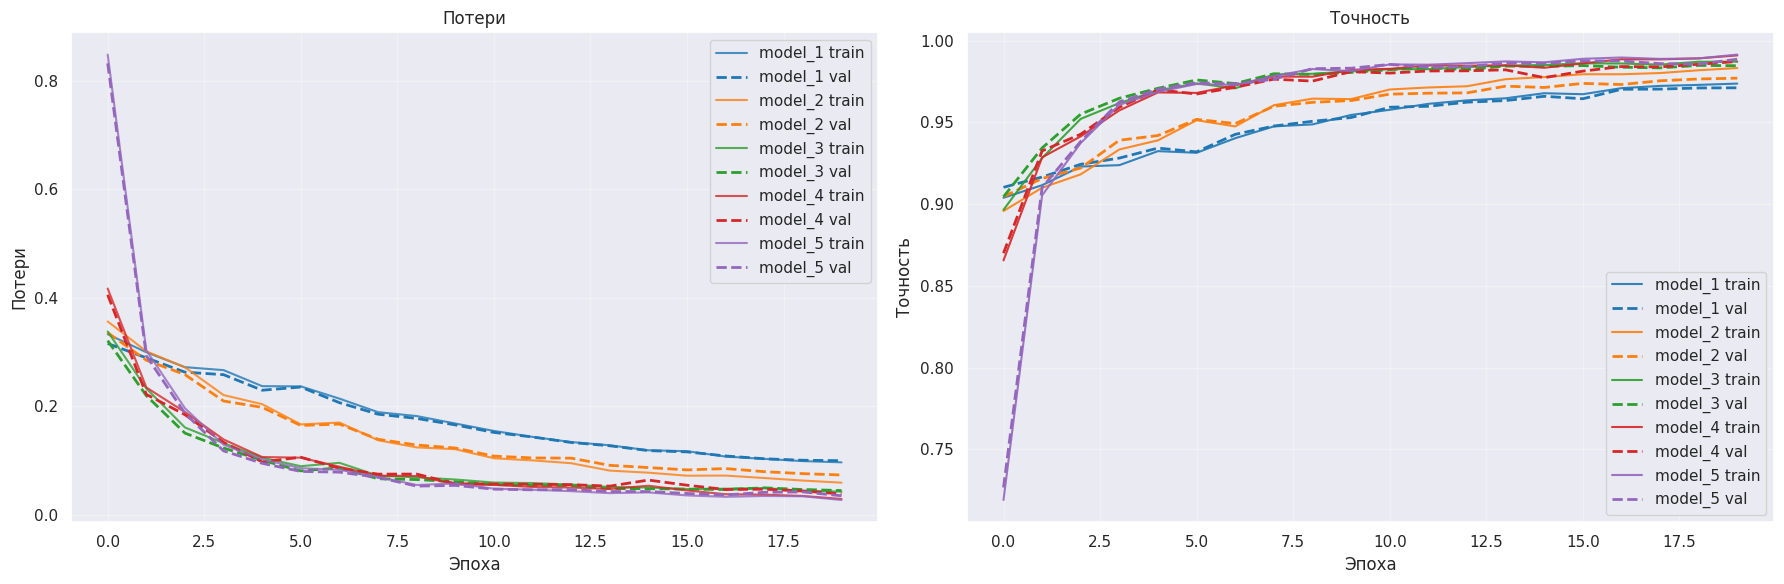

In [11]:
plt.figure(figsize=(18, 6))

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

plt.subplot(1, 2, 1)
for (model_name, result), color in zip(results.items(), colors):
    history = result["history"]
    plt.plot(history["train_loss"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.8)
    plt.plot(history["val_loss"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Потери")
plt.xlabel("Эпоха")
plt.ylabel("Потери")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for (model_name, result), color in zip(results.items(), colors):
    history = result["history"]
    plt.plot(history["train_acc"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.9)
    plt.plot(history["val_acc"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Точность")
plt.xlabel("Эпоха")
plt.ylabel("Точность")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

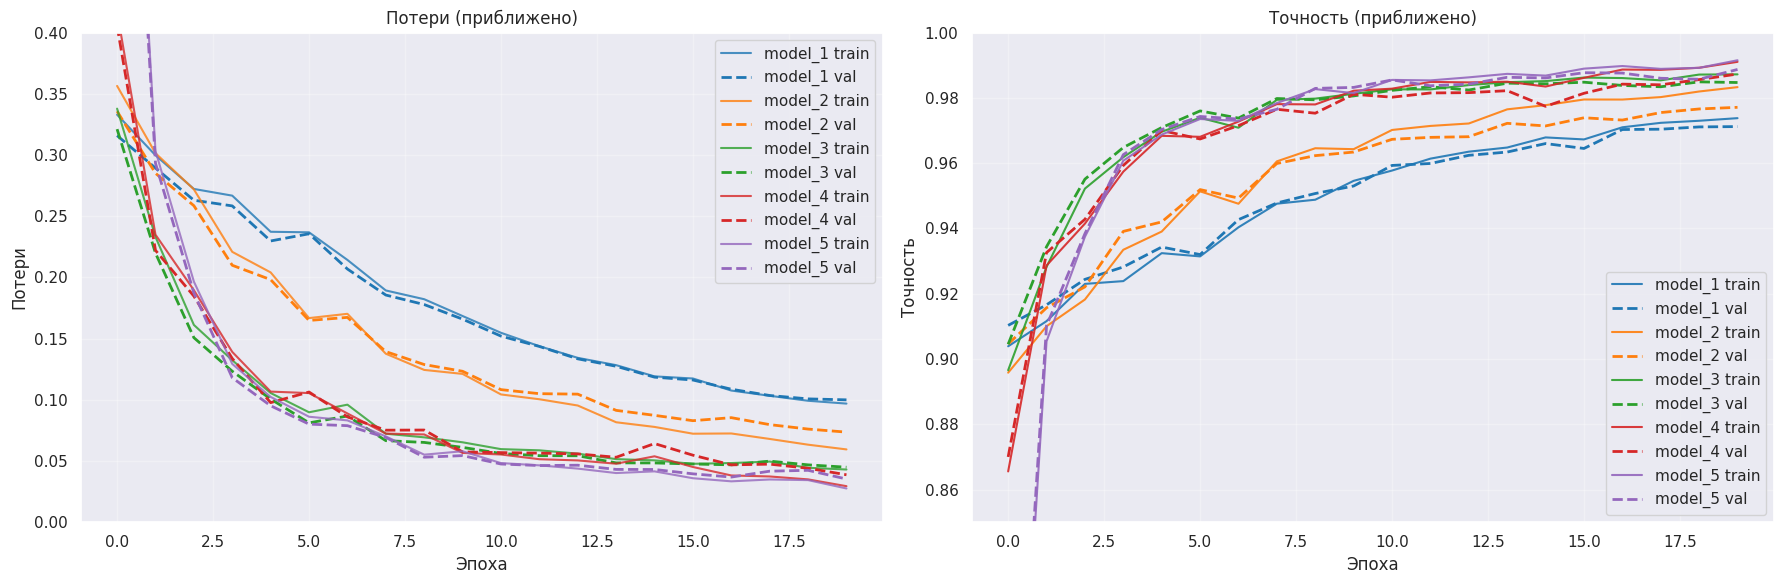

In [13]:
plt.figure(figsize=(18, 6))

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

plt.subplot(1, 2, 1)
for (model_name, result), color in zip(results.items(), colors):
    history = result["history"]
    plt.plot(history["train_loss"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.8)
    plt.plot(history["val_loss"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Потери (приближено)")
plt.xlabel("Эпоха")
plt.ylabel("Потери")
plt.ylim([0, 0.4])
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for (model_name, result), color in zip(results.items(), colors):
    history = result["history"]
    plt.plot(history["train_acc"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.9)
    plt.plot(history["val_acc"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Точность (приближено)")
plt.xlabel("Эпоха")
plt.ylabel("Точность")
plt.ylim([0.85, 1.0])
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

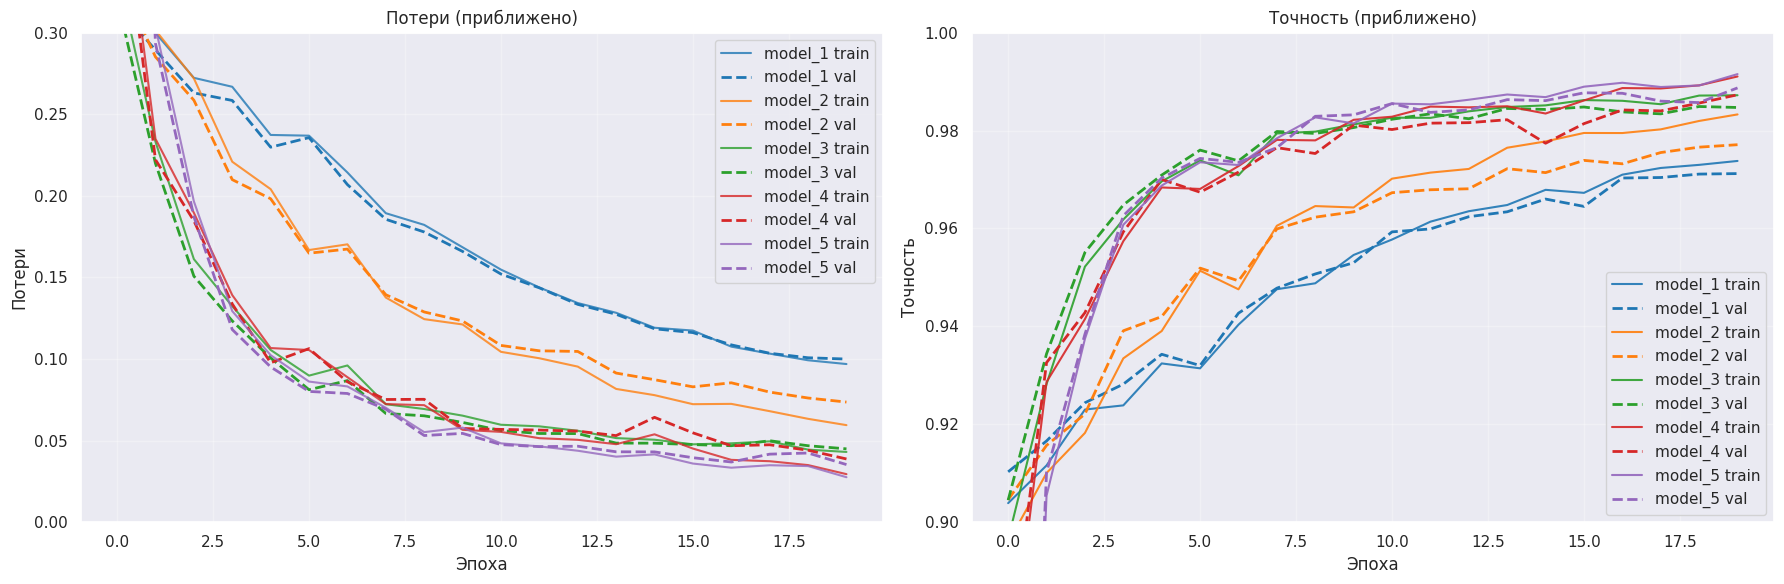

In [26]:
plt.figure(figsize=(18, 6))
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

plt.subplot(1, 2, 1)
for (model_name, result), color in zip(results.items(), colors):
    history = result["history"]
    plt.plot(history["train_loss"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.8)
    plt.plot(history["val_loss"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Потери (приближено)")
plt.xlabel("Эпоха")
plt.ylabel("Потери")
plt.ylim([0, 0.3])
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for (model_name, result), color in zip(results.items(), colors):
    history = result["history"]
    plt.plot(history["train_acc"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.9)
    plt.plot(history["val_acc"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Точность (приближено)")
plt.xlabel("Эпоха")
plt.ylabel("Точность")
plt.ylim([0.9, 1.0])
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Сделайте вывод. Как количество разных слоев влияет на качество и время обучения?

**Вывод по эксперименту:**

На графиках слева показано изменение функции потерь (loss), а справа — точности (accuracy) на обучающей и валидационной выборках для моделей с разным количеством сверточных и линейных слоёв.

Из графиков видно, что все модели успешно обучаются: loss уменьшается, а accuracy растёт уже с первых эпох. При этом более сложные архитектуры в среднем показывают более высокое итоговое качество. Простые модели, содержащие один сверточный слой, тоже достигают хорошей точности, но уступают более глубоким сетям.

Лучшие результаты показывают модели с более развитой сверточной частью, особенно `model_5`. К концу обучения она достигает `val_acc = 0.9887` (98.87%), а значение функции потерь снижается до очень малого уровня. Это означает, что более глубокая сеть лучше извлекает признаки изображения и точнее различает рукописные цифры.

Заметим, что сверточные слои выполняют локальный поиск паттернов: на первых слоях сеть выделяет простые элементы изображения, например линии, углы и дуги, а на более глубоких слоях комбинирует их в более сложные признаки. Поэтому увеличение числа сверточных слоев обычно улучшает качество распознавания.

Однако рост глубины сети увеличивает и время обучения. Более сложные модели обучаются дольше, так как содержат больше параметров и операций. Поэтому между качеством и скоростью возникает компромисс: простые модели быстрее, но немного слабее, а более глубокие модели точнее, но требуют больше времени.

Разница между train и val метриками у лучших моделей остаётся небольшой, поэтому признаков сильного переобучения не наблюдается. Это значит, что модели не просто запомнили обучающую выборку, а действительно научились распознавать закономерности в данных.

**3.** Теперь выберите лучший вариант, зафиксируйте это количество сверточных и линейных слоев и обучите 4 сверточных нейросети, варьируя размеры ядер сверток всех сверточных слоев нейросети: 3x3, 5x5, 7x7, 9x9.

In [14]:
def build_kernel_model(kernel_size):
    padding = kernel_size // 2  # сохраняем размер изображения после свертки

    model = nn.Sequential(
        nn.Conv2d(1, 32, kernel_size=kernel_size, stride=2, padding=padding),
        nn.ReLU(),

        nn.Conv2d(32, 64, kernel_size=kernel_size, padding=padding),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, kernel_size=kernel_size, padding=padding),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Flatten(),
        nn.Linear(128 * 3 * 3, 256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, 10)
    )
    return model


kernel_models = {
    "kernel_3x3": build_kernel_model(3),
    "kernel_5x5": build_kernel_model(5),
    "kernel_7x7": build_kernel_model(7),
    "kernel_9x9": build_kernel_model(9),
}

for model_name, model in kernel_models.items():
    print(f"\n{model_name}:")
    print(summary(model, input_size=(1, 1, 28, 28), device=device))

kernel_results = {}

for model_name, model in kernel_models.items():
    print(f"\n{model_name}:")
    trained_model, history, elapsed_time = train_model(
        model,
        train_loader,
        val_loader,
        num_epochs=20,
        device=device
    )

    kernel_results[model_name] = {
        "model": trained_model,
        "history": history,
        "time": elapsed_time
    }

    print(f"{model_name} обучена за {elapsed_time:.2f} сек")


kernel_3x3:
Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 10]                   --
├─Conv2d: 1-1                            [1, 32, 14, 14]           320
├─ReLU: 1-2                              [1, 32, 14, 14]           --
├─Conv2d: 1-3                            [1, 64, 14, 14]           18,496
├─ReLU: 1-4                              [1, 64, 14, 14]           --
├─MaxPool2d: 1-5                         [1, 64, 7, 7]             --
├─Conv2d: 1-6                            [1, 128, 7, 7]            73,856
├─ReLU: 1-7                              [1, 128, 7, 7]            --
├─MaxPool2d: 1-8                         [1, 128, 3, 3]            --
├─Flatten: 1-9                           [1, 1152]                 --
├─Linear: 1-10                           [1, 256]                  295,168
├─ReLU: 1-11                             [1, 256]                  --
├─Dropout: 1-12                          [1, 256]         

Постройте график лосса и график accuracy, где сравниваются все модели этого эксперимента (на train и на val).

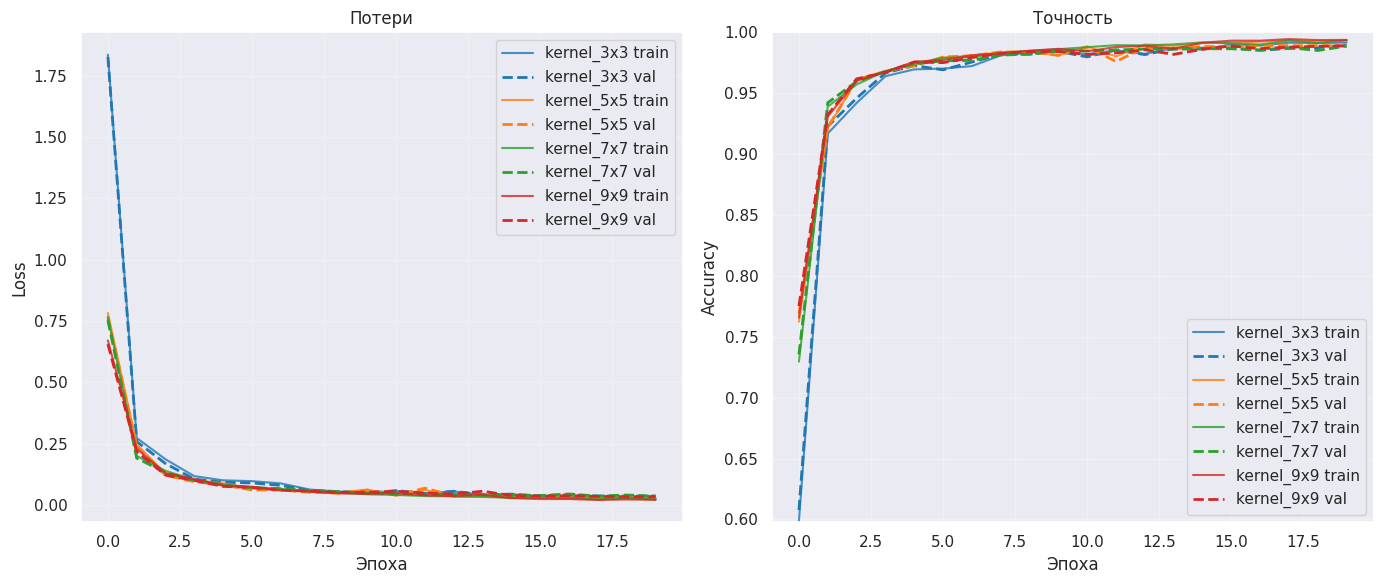


Итоговые val_accuracy:
kernel_3x3: 0.9896 (98.96%)
kernel_5x5: 0.9887 (98.87%)
kernel_7x7: 0.9887 (98.87%)
kernel_9x9: 0.9890 (98.90%)


In [16]:
plt.figure(figsize=(14, 6))

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

plt.subplot(1, 2, 1)
for (model_name, result), color in zip(kernel_results.items(), colors):
    history = result["history"]
    plt.plot(history["train_loss"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.8)
    plt.plot(history["val_loss"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Потери")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for (model_name, result), color in zip(kernel_results.items(), colors):
    history = result["history"]
    plt.plot(history["train_acc"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.8)
    plt.plot(history["val_acc"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Точность")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")

# Масштаб по оси Y
all_val_accs = [v for r in kernel_results.values() for v in r["history"]["val_acc"]]
plt.ylim([max(0, min(all_val_accs) - 0.01), 1.0])

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nИтоговые val_accuracy:")
for model_name, result in kernel_results.items():
    final_acc = result["history"]["val_acc"][-1]
    print(f"{model_name}: {final_acc:.4f} ({final_acc*100:.2f}%)")

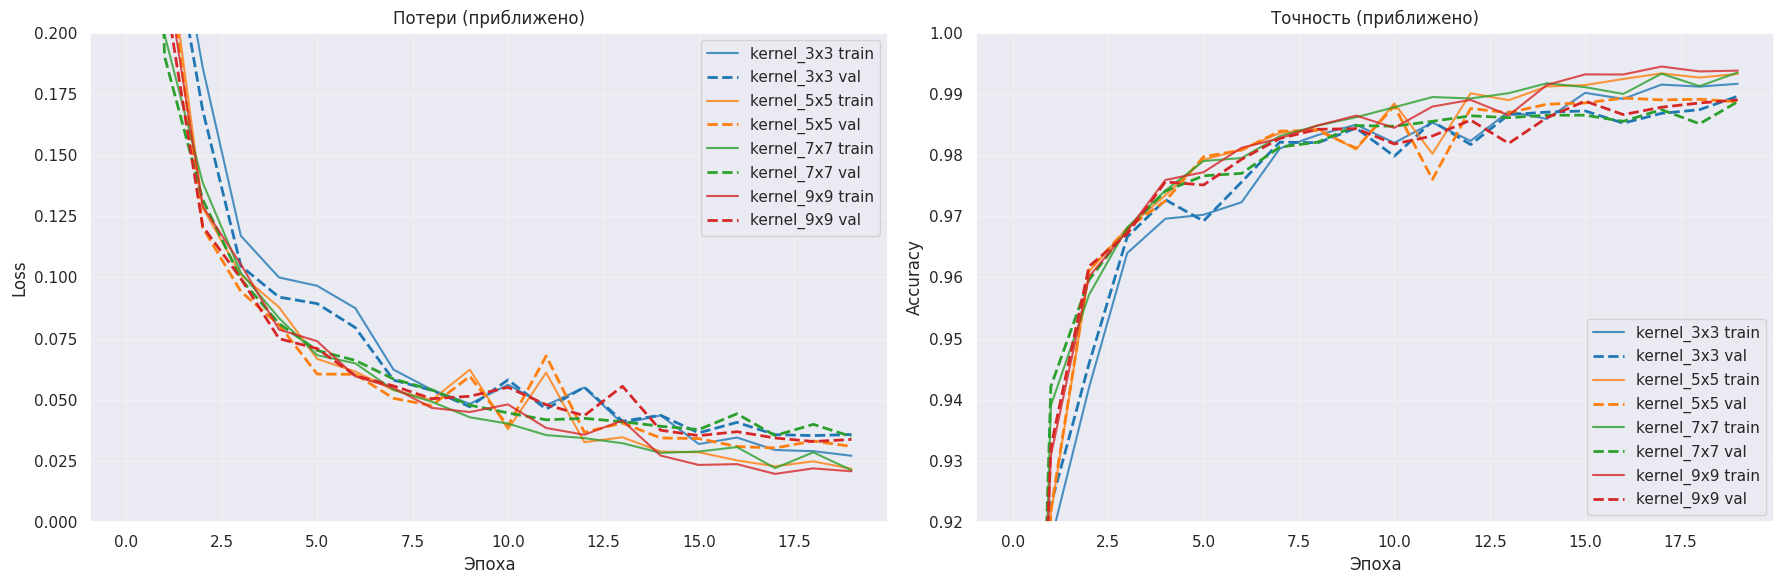


Итоговые val_accuracy:
kernel_3x3: 0.9896 (98.96%)
kernel_5x5: 0.9887 (98.87%)
kernel_7x7: 0.9887 (98.87%)
kernel_9x9: 0.9890 (98.90%)


In [19]:
plt.figure(figsize=(18, 6))

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

plt.subplot(1, 2, 1)
for (model_name, result), color in zip(kernel_results.items(), colors):
    history = result["history"]
    plt.plot(history["train_loss"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.8)
    plt.plot(history["val_loss"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Потери (приближено)")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.ylim([0, 0.20])
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for (model_name, result), color in zip(kernel_results.items(), colors):
    history = result["history"]
    plt.plot(history["train_acc"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.8)
    plt.plot(history["val_acc"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Точность (приближено)")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.ylim([0.92, 1.0])
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nИтоговые val_accuracy:")
for model_name, result in kernel_results.items():
    final_acc = result["history"]["val_acc"][-1]
    print(f"{model_name}: {final_acc:.4f} ({final_acc*100:.2f}%)")

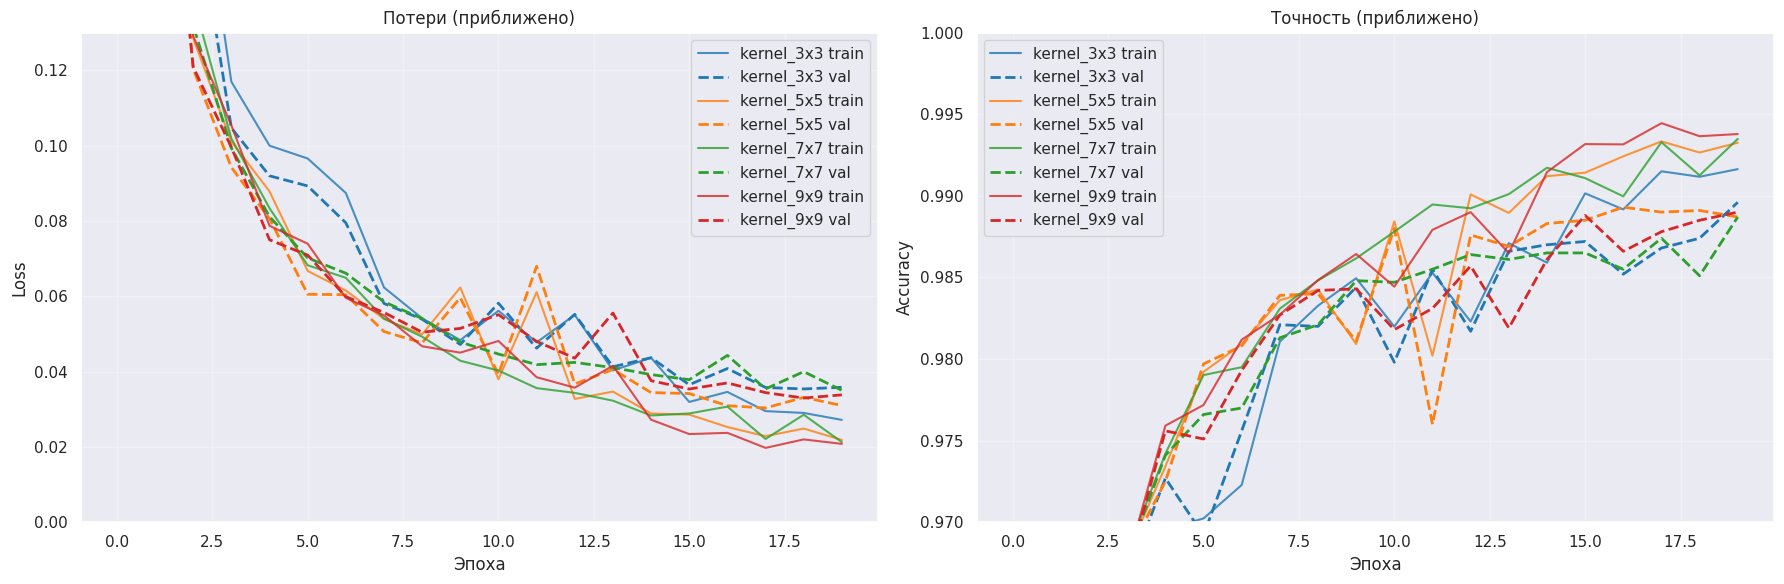


Итоговые val_accuracy:
kernel_3x3: 0.9896 (98.96%)
kernel_5x5: 0.9887 (98.87%)
kernel_7x7: 0.9887 (98.87%)
kernel_9x9: 0.9890 (98.90%)


In [22]:
plt.figure(figsize=(18, 6))

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

plt.subplot(1, 2, 1)
for (model_name, result), color in zip(kernel_results.items(), colors):
    history = result["history"]
    plt.plot(history["train_loss"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.8)
    plt.plot(history["val_loss"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Потери (приближено)")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.ylim([0, 0.13])
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for (model_name, result), color in zip(kernel_results.items(), colors):
    history = result["history"]
    plt.plot(history["train_acc"], label=f"{model_name} train", color=color, linestyle="-", linewidth=1.5, alpha=0.8)
    plt.plot(history["val_acc"], label=f"{model_name} val", color=color, linestyle="--", linewidth=2)
plt.title("Точность (приближено)")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.ylim([0.97, 1.0])
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nИтоговые val_accuracy:")
for model_name, result in kernel_results.items():
    final_acc = result["history"]["val_acc"][-1]
    print(f"{model_name}: {final_acc:.4f} ({final_acc*100:.2f}%)")

Сделайте вывод. Как размеры ядер влияют на качество и время обучения?

**Вывод по эксперименту:**

На графиках слева показано изменение функции потерь, а справа — точности на обучающей и валидационной выборках для моделей с разным размером ядра свёртки.

По графикам видно, что все модели обучаются успешно: loss быстро уменьшается уже на первых эпохах, а accuracy растёт и к концу обучения у всех моделей достигает очень высокого уровня — около 0.98–0.99 на валидации. Это означает, что все рассмотренные размеры ядра подходят для задачи MNIST, но между ними всё же есть различия по качеству и скорости обучения.

Лучший результат показала модель `kernel_3x3`: её максимальная точность на валидации составила `0.9896` (98.96%). Сделаем вывод, что маленькие ядра лучше выделяют локальные паттерны изображения, такие как короткие линии, изгибы, углы и пересечения, из которых и состоят рукописные цифры. Затем более глубокие слои комбинируют эти простые признаки в более сложные.

Модели с более крупными ядрами (`5x5`, `7x7`, `9x9`) тоже достигли высокой точности, но не дали заметного выигрыша по качеству. При этом увеличение ядра увеличивает число параметров и время обучения. Поэтому большие ядра в данной задаче оказались менее выгодными: они захватывают более широкую область изображения, но для MNIST такой широкий контекст не даёт существенного преимущества.

Таким образом, размер ядра влияет не только на качество, но и на вычислительную эффективность. В данном эксперименте наилучшим оказался вариант с ядром `3x3`.

**4.** Выберите лучшую конфигурацию из всех по accuracy на валидации. Она должна быть не меньше 97%.

In [27]:
best_model_name = max(
    kernel_results,
    key=lambda name: max(kernel_results[name]["history"]["val_acc"])  # максимальная val_acc за все эпохи
)

best_model = kernel_results[best_model_name]["model"]
best_history = kernel_results[best_model_name]["history"]
best_time = kernel_results[best_model_name]["time"]
best_val_acc = max(best_history["val_acc"])

print("Лучшая модель:", best_model_name)
print(f"Лучшая val accuracy: {best_val_acc:.4f} ({best_val_acc*100:.2f}%)")
print(f"Время обучения: {best_time:.2f} сек")

Лучшая модель: kernel_3x3
Лучшая val accuracy: 0.9896 (98.96%)
Время обучения: 360.25 сек


Проведите еще один проход валидации выбранной моделью по всему датасету. В нем посчитайте точность по каждому классу и соберите информацию о неправильных предсказаниях. Равномерна ли точность по отношению к классам? Покажите 10-20 примеров, на которых нейросеть выдала неправильную метку. Что можно о них сказать?

Общая точность на валидации: 0.9896 (98.96%)
Точность по классам:
  Класс 0: 0.9969
  Класс 1: 0.9965
  Класс 2: 0.9942
  Класс 3: 0.9911
  Класс 4: 0.9919
  Класс 5: 0.9877
  Класс 6: 0.9875
  Класс 7: 0.9883
  Класс 8: 0.9836
  Класс 9: 0.9772

Разброс точности: min=0.9772, max=0.9969, разница=0.0197
Точность равномерна по классам
Количество ошибок: 104


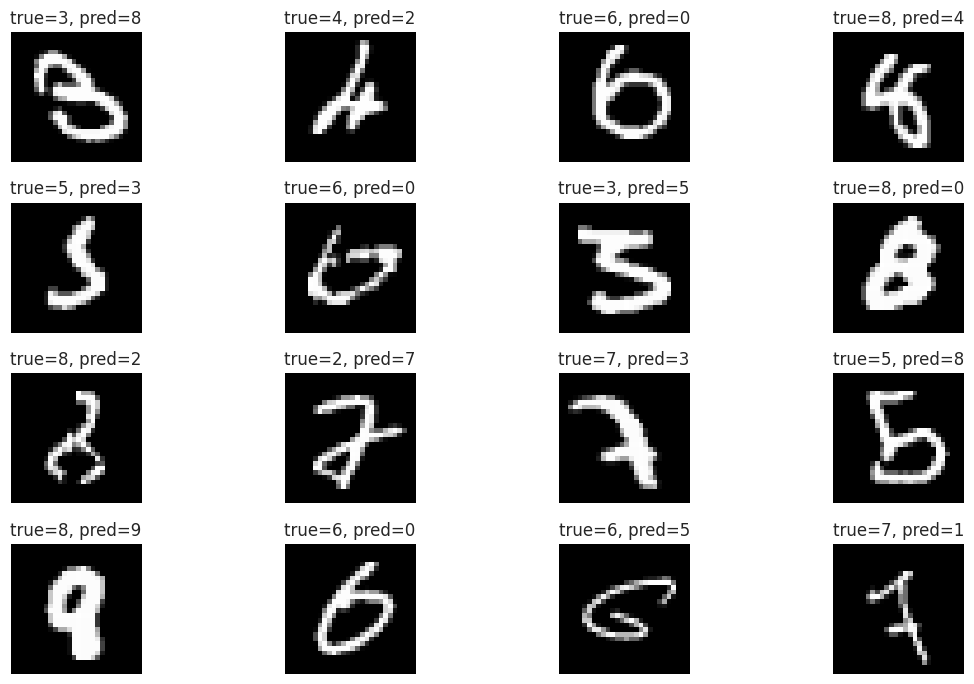

In [28]:
# Сбор предсказаний по всему валидационному датасету
all_preds = []
all_labels = []
all_images = []

best_model.eval()
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = best_model(images)
        preds = logits.argmax(dim=1)

        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())
        all_images.append(images.cpu())

# Объединяем все батчи
all_preds = torch.cat(all_preds)
all_labels = torch.cat(all_labels)
all_images = torch.cat(all_images)

# Общая точность
overall_acc = (all_preds == all_labels).float().mean().item()
print(f"Общая точность на валидации: {overall_acc:.4f} ({overall_acc*100:.2f}%)")

# Точность по каждому классу
class_accuracy = {}
for class_id in range(num_classes):
    mask = all_labels == class_id
    if mask.sum() > 0:
        class_acc = (all_preds[mask] == all_labels[mask]).float().mean().item()
        class_accuracy[class_id] = class_acc

print("Точность по классам:")
for class_id, acc in class_accuracy.items():
    print(f"  Класс {class_id}: {acc:.4f}")

# Проверка равномерности точности
acc_values = list(class_accuracy.values())
min_acc = min(acc_values)
max_acc = max(acc_values)

print(f"\nРазброс точности: min={min_acc:.4f}, max={max_acc:.4f}, разница={(max_acc-min_acc):.4f}")

if max_acc - min_acc > 0.05:
    print("Точность неравномерна по классам")
else:
    print("Точность равномерна по классам")

# Собираем неправильные предсказания
wrong_mask = all_preds != all_labels
wrong_images = all_images[wrong_mask]
wrong_preds = all_preds[wrong_mask]
wrong_labels = all_labels[wrong_mask]

print("Количество ошибок:", len(wrong_images))

num_examples = min(16, len(wrong_images))

plt.figure(figsize=(12, 7))
for i in range(num_examples):
    plt.subplot(4, 4, i + 1)
    plt.imshow(wrong_images[i].squeeze(0), cmap="gray")
    plt.title(f"true={wrong_labels[i].item()}, pred={wrong_preds[i].item()}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [29]:
# Простой анализ ошибок
print("\nАнализ ошибок:")
print("="*50)

# Считаем пары ошибок вручную
error_pairs = {}
for true, pred in zip(wrong_labels, wrong_preds):
    true = true.item()
    pred = pred.item()
    pair = (true, pred)
    error_pairs[pair] = error_pairs.get(pair, 0) + 1

# Находим 5 самых частых ошибок
sorted_errors = sorted(error_pairs.items(), key=lambda x: x[1], reverse=True)[:5]

print("Самые частые ошибки (истинный -> предсказанный):")
for (true, pred), count in sorted_errors:
    print(f"  {true} → {pred}: {count} раз(а)")

# Считаем для каждого класса
print("\nДля каждого класса, с чем чаще всего путают:")
for class_id in range(10):
    # Собираем ошибки для этого класса
    class_errors = {}
    for true, pred in zip(wrong_labels, wrong_preds):
        true = true.item()
        pred = pred.item()
        if true == class_id:
            class_errors[pred] = class_errors.get(pred, 0) + 1

    if class_errors:
        # Находим самый частый
        most_common = max(class_errors.items(), key=lambda x: x[1])
        print(f"  Класс {class_id} чаще всего путают с {most_common[0]} ({most_common[1]} раз)")


Анализ ошибок:
Самые частые ошибки (истинный -> предсказанный):
  9 → 4: 7 раз(а)
  7 → 2: 6 раз(а)
  6 → 0: 5 раз(а)
  5 → 3: 5 раз(а)
  8 → 0: 5 раз(а)

Для каждого класса, с чем чаще всего путают:
  Класс 0 чаще всего путают с 6 (1 раз)
  Класс 1 чаще всего путают с 2 (2 раз)
  Класс 2 чаще всего путают с 0 (3 раз)
  Класс 3 чаще всего путают с 8 (4 раз)
  Класс 4 чаще всего путают с 2 (3 раз)
  Класс 5 чаще всего путают с 3 (5 раз)
  Класс 6 чаще всего путают с 0 (5 раз)
  Класс 7 чаще всего путают с 2 (6 раз)
  Класс 8 чаще всего путают с 0 (5 раз)
  Класс 9 чаще всего путают с 4 (7 раз)


**Ответ:**

После выбора лучшей модели был выполнен дополнительный проход по всей валидационной выборке. Общая точность модели оказалась очень высокой, а точность по отдельным классам лежит в диапазоне от `97.72%` до `99.69%`.

Это значит, что точность по классам в целом достаточно равномерна. Хотя некоторые цифры распознаются немного хуже других, разброс между минимальной и максимальной точностью составляет всего `0.0197`. Следовательно, модель хорошо работает на всех цифрах.

Анализ неправильных предсказаний показывает, что ошибки возникают в основном на неоднозначных примерах. Чаще всего модель путает визуально похожие цифры: `9` и `4`, `7` и `2`, `6` и `0`, `5` и `3`, `8` и `0`. На показанных ошибочных изображениях видно, что цифры нередко написаны нестандартно, имеют необычный наклон, разрывы в линиях или форму, похожую на другой класс.

Таким образом, модель ошибается в основном не на простых и хорошо написанных примерах, а на тех изображениях, где даже человеку иногда сложнее однозначно определить цифру. Это говорит о том, что модель хорошо выделяет характерные признаки классов и допускает ошибки в основном на сложных случаях.

**5.** **Вывод по всей задаче:**

В эксперименте 1 сравнивались модели с разным числом сверточных и линейных слоёв.
Увеличение глубины сети (добавление второго сверточного слоя) заметно улучшало качество: **model_3** достигла точности 98.47% по сравнению с **model_2** 97.71%, тогда как добавление второго линейного слоя к двум сверточным **(model_4)** давало меньший прирост - 98.73% против 98.47% у **model_3**. **Лучший результат (98.87%) показала модель с тремя сверточными слоями (model_5).**

В эксперименте 2 варьировался размер ядра свёртки `(3×3, 5×5, 7×7, 9×9)` во всех
сверточных слоях. Наилучшее качество показало ядро `3×3`, тогда как увеличение размера
ядра не давало прироста точности и незначительно замедляло обучение.

В качестве лучшей конфигурации была выбрана модель `kernel_3x3`, так как она показала максимальную точность на валидации — `98.96%`, что заметно выше `97%`.

Дополнительная проверка по всему валидационному датасету показала, что модель работает стабильно для всех классов: точность по отдельным цифрам находится в диапазоне от `97.72%` до `99.69%`, а разброс между классами невелик. Это говорит о хорошем качестве обобщения и отсутствии сильного перекоса по классам.

Анализ ошибок показал, что нейросеть чаще всего путает визуально похожие цифры, особенно если они написаны неаккуратно, наклонно или нестандартным способом. Значит, модель в целом решает задачу успешно, а большинство её ошибок связано именно со сложными и неоднозначными примерами.

---
### Задача 2. Визуализиция сверточных слоев

Обучите модель, состоящую как минимум из 4 сверточных слоев, на датасете MNIST. **Количество выходных каналов в каждом сверточном слое должно быть равно 32**, а точность на тестовых данных должна достигать 97%. Для создания модели будет удобно использовать `torch.nn.Sequential`.


In [28]:
deep_model = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),

    nn.Conv2d(32, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 32, kernel_size=3, padding=1),
    nn.ReLU(),

    nn.Conv2d(32, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 10)
).to(device)

print(deep_model)

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU()
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU()
  (7): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU()
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Flatten(start_dim=1, end_dim=-1)
  (11): Linear(in_features=1568, out_features=128, bias=True)
  (12): ReLU()
  (13): Dropout(p=0.3, inplace=False)
  (14): Linear(in_features=128, out_features=10, bias=True)
)


In [29]:
print("\nСводка по модели:")
summary(deep_model, input_size=(1, 1, 28, 28), device=device)


Сводка по модели:


Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 10]                   --
├─Conv2d: 1-1                            [1, 32, 28, 28]           320
├─ReLU: 1-2                              [1, 32, 28, 28]           --
├─Conv2d: 1-3                            [1, 32, 28, 28]           9,248
├─ReLU: 1-4                              [1, 32, 28, 28]           --
├─MaxPool2d: 1-5                         [1, 32, 14, 14]           --
├─Conv2d: 1-6                            [1, 32, 14, 14]           9,248
├─ReLU: 1-7                              [1, 32, 14, 14]           --
├─Conv2d: 1-8                            [1, 32, 14, 14]           9,248
├─ReLU: 1-9                              [1, 32, 14, 14]           --
├─MaxPool2d: 1-10                        [1, 32, 7, 7]             --
├─Flatten: 1-11                          [1, 1568]                 --
├─Linear: 1-12                           [1, 128]                  200,832


In [30]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(deep_model.parameters(), lr=0.01)

trained_model, history, elapsed_time = train_model(
    deep_model,
    train_loader,
    val_loader,
    num_epochs=20,
    device=device
)

best_val_acc = max(history["val_acc"])
best_epoch = history["val_acc"].index(best_val_acc) + 1

print(f"Лучшая val accuracy: {best_val_acc:.4f} ({best_val_acc*100:.2f}%)")
print(f"Достигнута на эпохе: {best_epoch}")
print(f"Время обучения: {elapsed_time:.2f} сек")

Epoch 1: train_loss=0.4246, train_acc=0.8678, val_loss=0.4035, val_acc=0.8800
Epoch 2: train_loss=0.1794, train_acc=0.9444, val_loss=0.1722, val_acc=0.9467
Epoch 3: train_loss=0.1188, train_acc=0.9629, val_loss=0.1137, val_acc=0.9628
Epoch 4: train_loss=0.0979, train_acc=0.9697, val_loss=0.0917, val_acc=0.9714
Epoch 5: train_loss=0.0642, train_acc=0.9797, val_loss=0.0637, val_acc=0.9808
Epoch 6: train_loss=0.0535, train_acc=0.9833, val_loss=0.0532, val_acc=0.9824
Epoch 7: train_loss=0.0472, train_acc=0.9858, val_loss=0.0482, val_acc=0.9841
Epoch 8: train_loss=0.0450, train_acc=0.9858, val_loss=0.0462, val_acc=0.9843
Epoch 9: train_loss=0.0422, train_acc=0.9869, val_loss=0.0462, val_acc=0.9846
Epoch 10: train_loss=0.0333, train_acc=0.9898, val_loss=0.0371, val_acc=0.9880
Epoch 11: train_loss=0.0295, train_acc=0.9912, val_loss=0.0349, val_acc=0.9889
Epoch 12: train_loss=0.0299, train_acc=0.9906, val_loss=0.0358, val_acc=0.9879
Epoch 13: train_loss=0.0282, train_acc=0.9912, val_loss=0.035

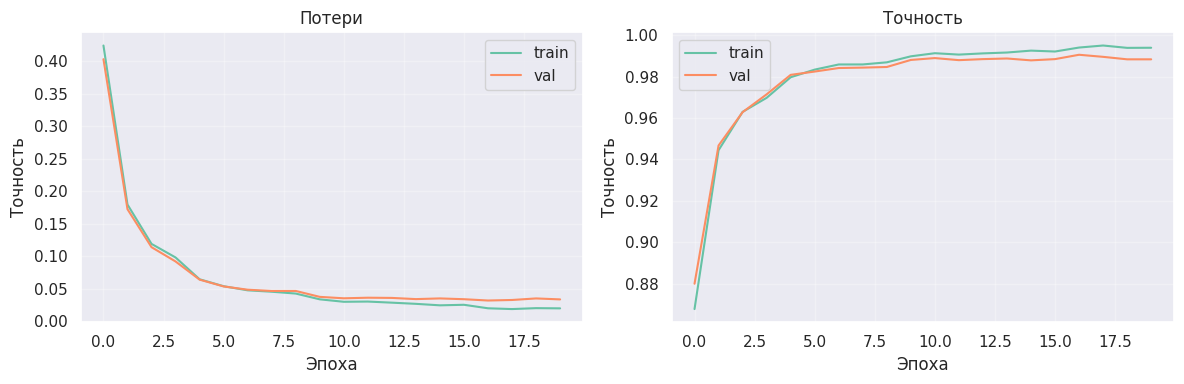

In [31]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.title("Потери")
plt.xlabel("Эпоха")
plt.ylabel("Точность")
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="train")
plt.plot(history["val_acc"], label="val")
plt.title("Точность")
plt.xlabel("Эпоха")
plt.ylabel("Точность")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### Вывод по обучению модели

На графиках показано изменение функции потерь (loss) и точности (accuracy) на обучающей и валидационной выборках по эпохам.

Модель демонстрирует стабильное и быстрое обучение. На первой эпохе точность составляет `0.8678` (train) и `0.8800` (val), что значительно выше случайного угадывания. Уже к третьей эпохе качество достигает высоких значений: `train_acc = 0.9629`, `val_acc = 0.9628`, а значение функции потерь снижается с `0.4246` до `0.1188`.

Далее обучение продолжается плавно: к 10-й эпохе достигается `val_acc = 0.9880`, а к 17-й эпохе — максимальное значение `0.9905`. При этом значения `train_acc = 0.9940` и `val_acc = 0.9905` близки друг к другу, что говорит об отсутствии сильного переобучения.

Функция потерь также стабильно уменьшается и к концу обучения достигает `val_loss = 0.0315`.

Таким образом, модель успешно обучается, быстро сходится и достигает высокой точности (`99.05%`) без признаков переобучения.

Визуализируйте веса свертки на первом слое. Поскольку веса имеют размерность $(32, 1, K_1, K_2)$, т.к. входное изображение имеет один канал, вам необходимо отобразить 32 изображения (по количеству выходных каналов) фильтрами размера $K_1 \times K_2$.

*Совет.* Здесь и далее серии из 32 картинок визуализируйте в виде сетки с помощью `plt.subplots(4, 8, figsize=...)`. Не забывайте указывать параметр `cmap='gray'`.

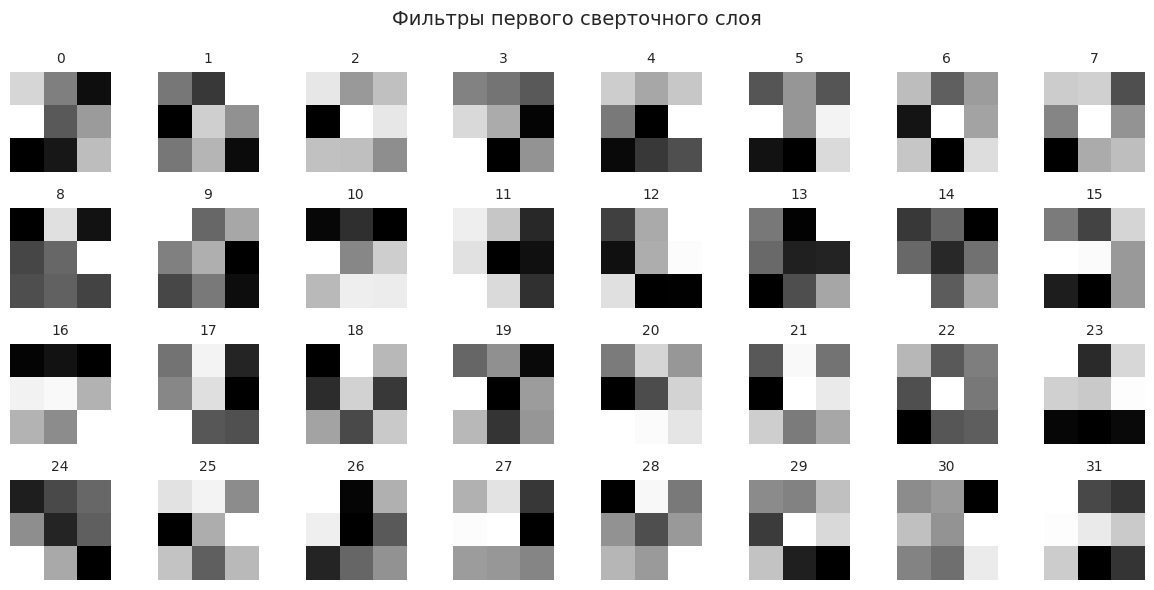

In [32]:
first_conv = None
for layer in deep_model:
    if isinstance(layer, nn.Conv2d):
        first_conv = layer
        break

weights = first_conv.weight.detach().cpu()

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
fig.suptitle("Фильтры первого сверточного слоя", fontsize=14)

for i, ax in enumerate(axes.flat):
    kernel = weights[i, 0]
    ax.imshow(kernel, cmap="gray")
    ax.axis("off")
    ax.set_title(f"{i}", fontsize=10)

plt.tight_layout()
plt.show()

Какую функцию они могут нести? Для ответа на вопрос вспомните фильтры, рассмотренные на семинаре.

**Ответ:** Фильтры первого сверточного слоя выполняют функцию детекторов простых визуальных признаков. Часть фильтров реагирует на вертикальные или горизонтальные линии, часть — на переходы яркости (границы), часть — на тёмный или светлый цвет в локальной области изображения.

### Вывод по фильтрам первого сверточного слоя

На изображении показаны фильтры первого сверточного слоя — это прямая визуализация весов слоя.

Светлые пиксели соответствуют положительным весам, тёмные — отрицательным.
Часть фильтров реагирует на горизонтальные или вертикальные линии, часть —
на переходы от светлого к тёмному или наоборот (контрастные границы).
Некоторые фильтры реагируют преимущественно на светлый или тёмный цвет в целом.

Таким образом, первый сверточный слой выполняет роль детектора базовых признаков изображения.

Для одного произвольного изображения из датасета MNIST визуализируйте выходы **всех слоев** нейросети, включая активацию и пуллинг, вплоть до операции `Flatten`, но не включая её. Каждый выход будет иметь размерность $(32, H_i, W_i)$. Таким образом, для каждого слоя необходимо создать $32$ изображения размером $H_i \times W_i$.

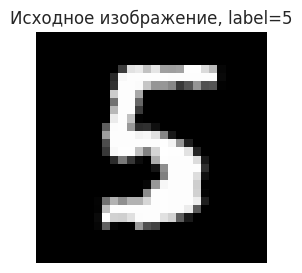

In [33]:
# Берем одно произвольное изображение
data_iter = iter(train_loader)
images, labels = next(data_iter)
img = images[0:1].to(device)  # первое
label = labels[0].item()

plt.figure(figsize=(3, 3))
plt.imshow(img[0, 0].cpu(), cmap="gray")
plt.title(f"Исходное изображение, label={label}")
plt.axis("off")
plt.show()

In [34]:
# Собираем выходы всех слоев до Flatten (ReLU и MaxPool тоже)
outputs = []
layer_names = []

x = img
for i, layer in enumerate(deep_model):
    if isinstance(layer, nn.Flatten):
        break
    x = layer(x)
    outputs.append((layer, x.detach().cpu()))  # сохраняем пару (слой, тензор)
    layer_names.append(f"{i}: {layer.__class__.__name__}")

print("Слои для визуализации:")
for name, (layer, tensor) in zip(layer_names, outputs):
    print(name, tensor.shape)

Слои для визуализации:
0: Conv2d torch.Size([1, 32, 28, 28])
1: ReLU torch.Size([1, 32, 28, 28])
2: Conv2d torch.Size([1, 32, 28, 28])
3: ReLU torch.Size([1, 32, 28, 28])
4: MaxPool2d torch.Size([1, 32, 14, 14])
5: Conv2d torch.Size([1, 32, 14, 14])
6: ReLU torch.Size([1, 32, 14, 14])
7: Conv2d torch.Size([1, 32, 14, 14])
8: ReLU torch.Size([1, 32, 14, 14])
9: MaxPool2d torch.Size([1, 32, 7, 7])


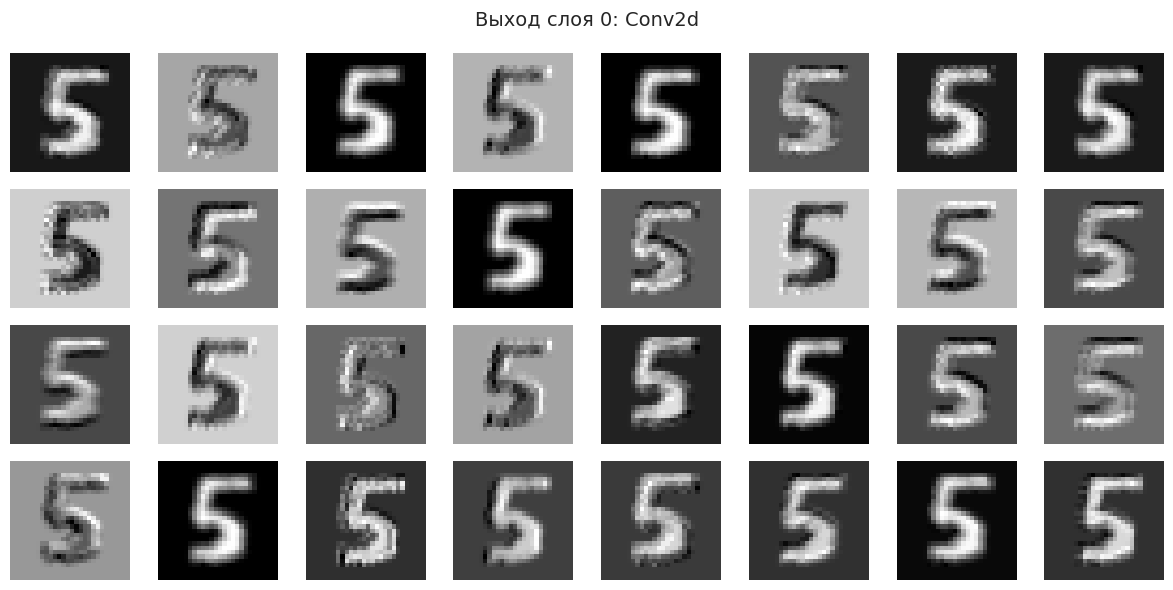

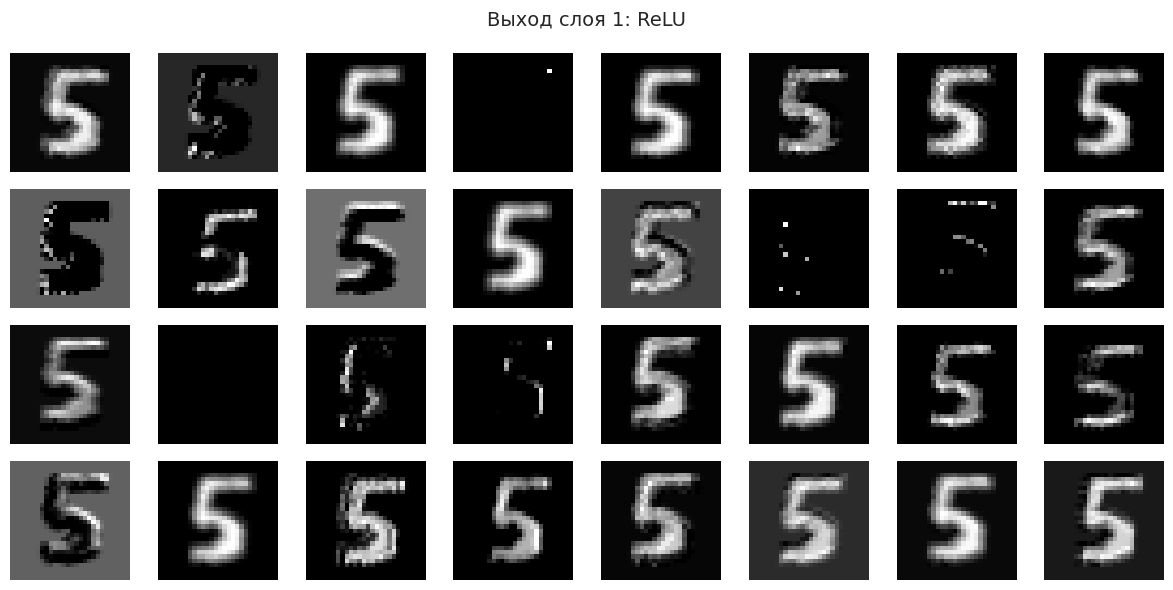

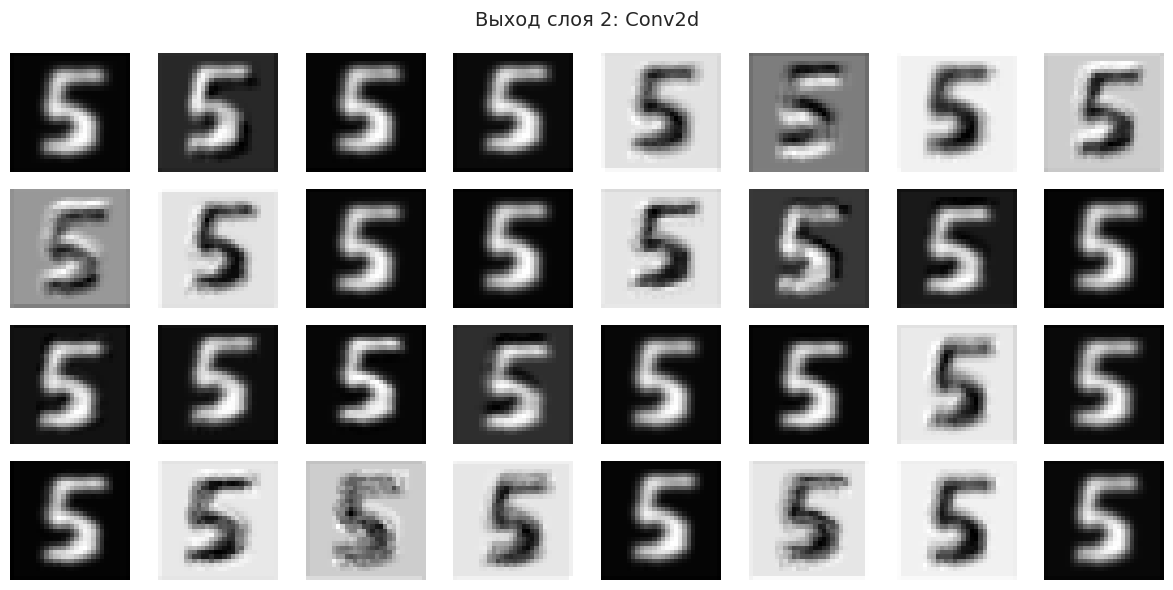

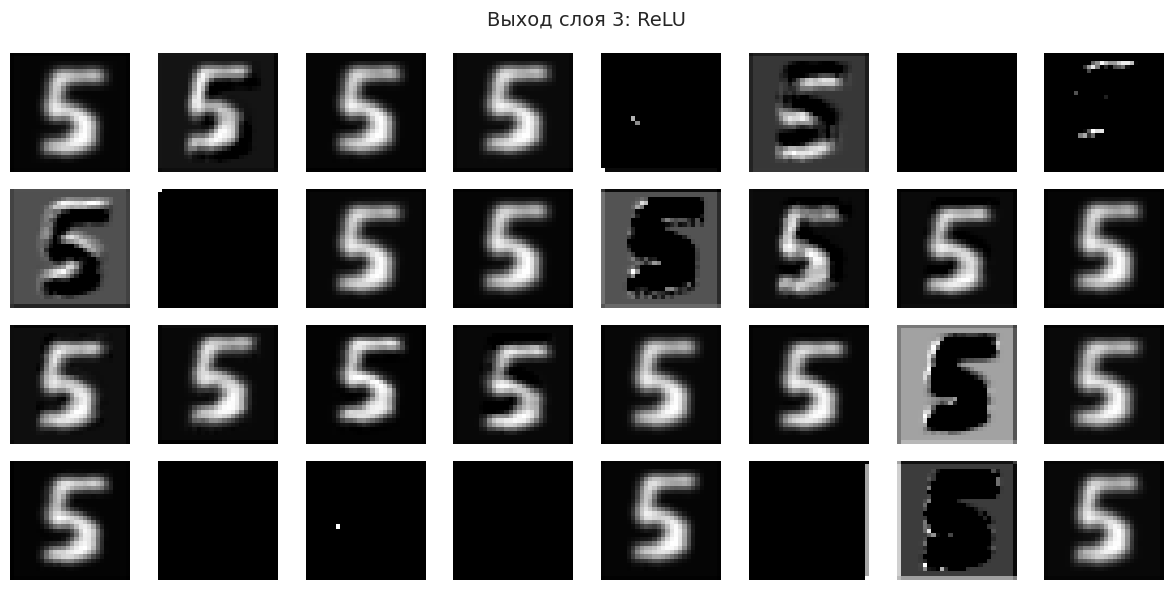

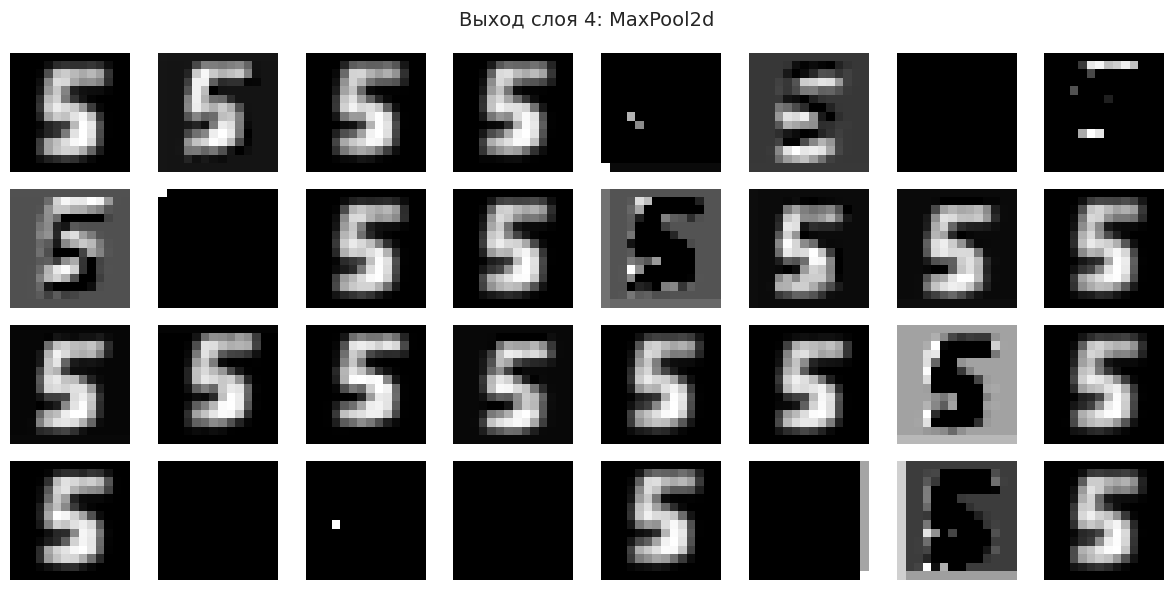

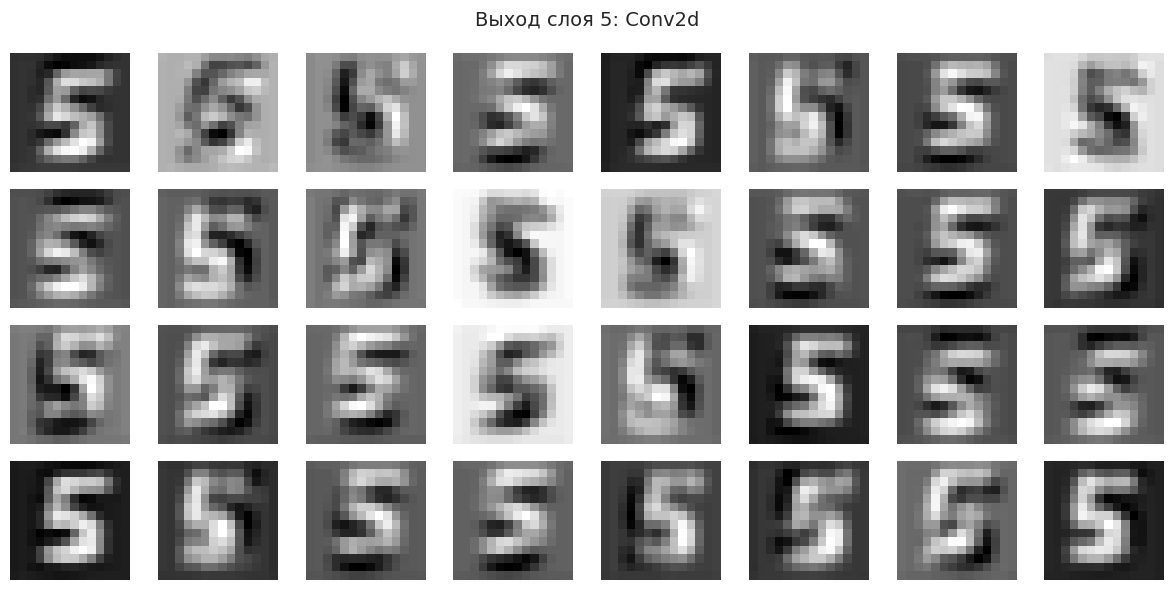

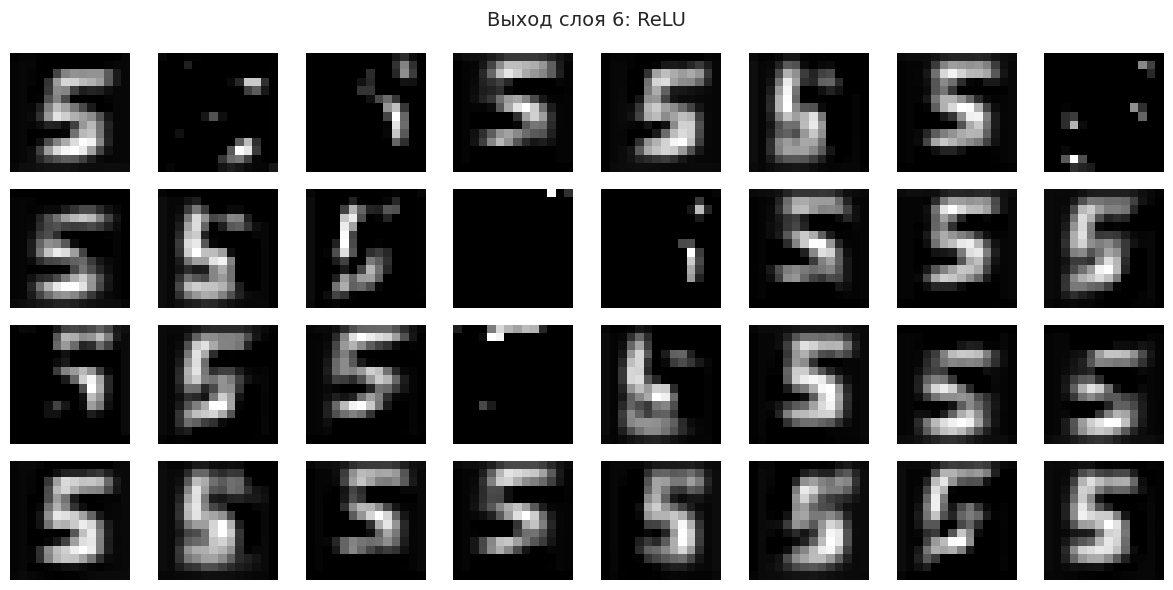

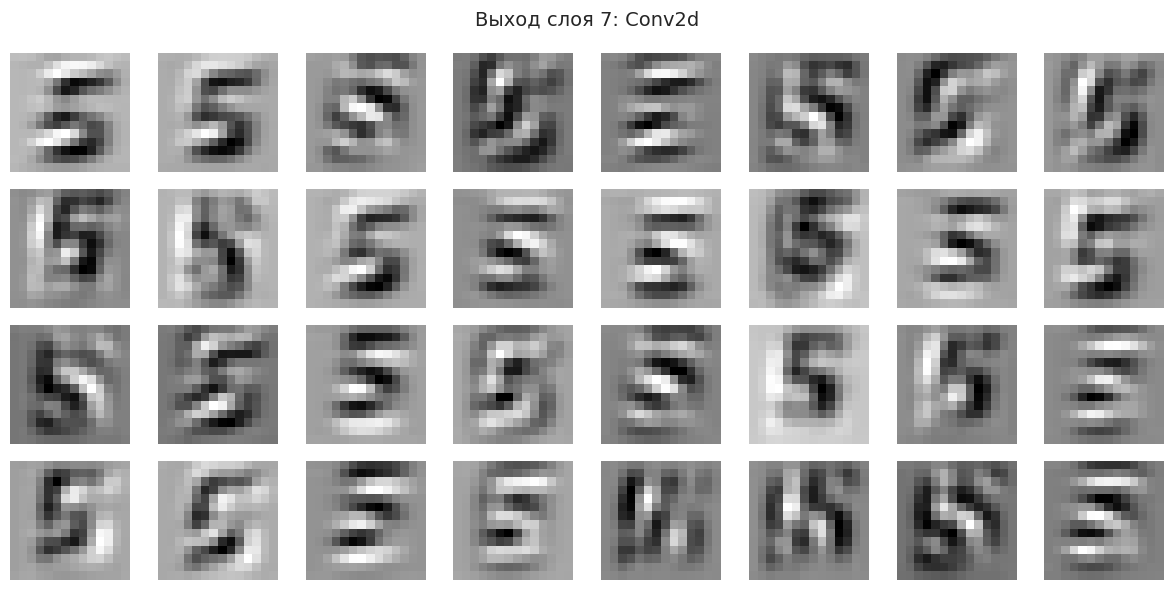

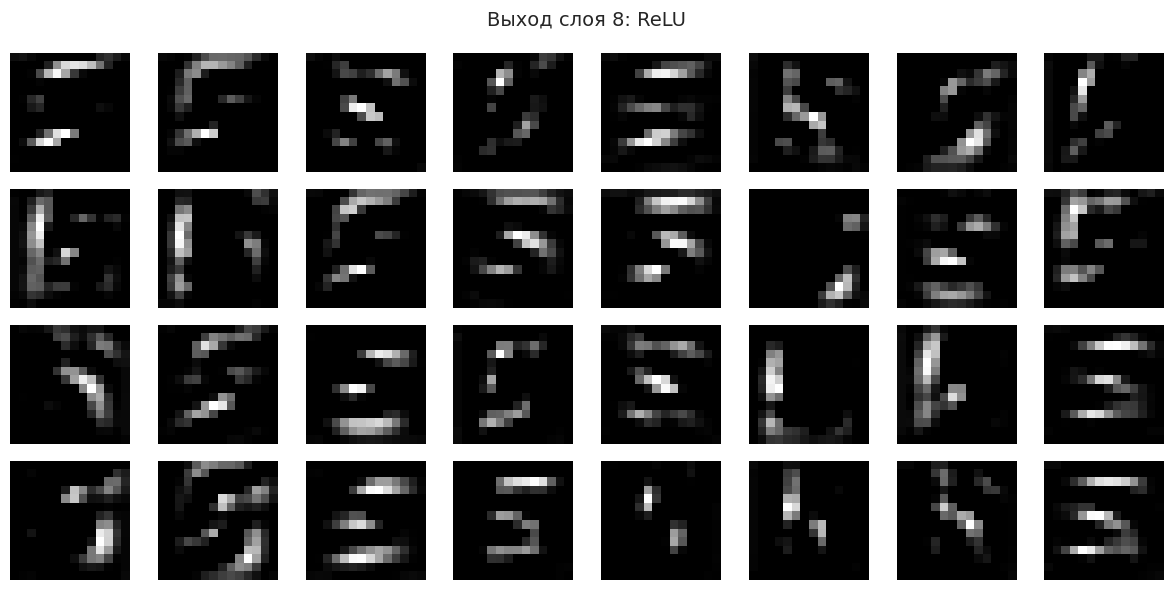

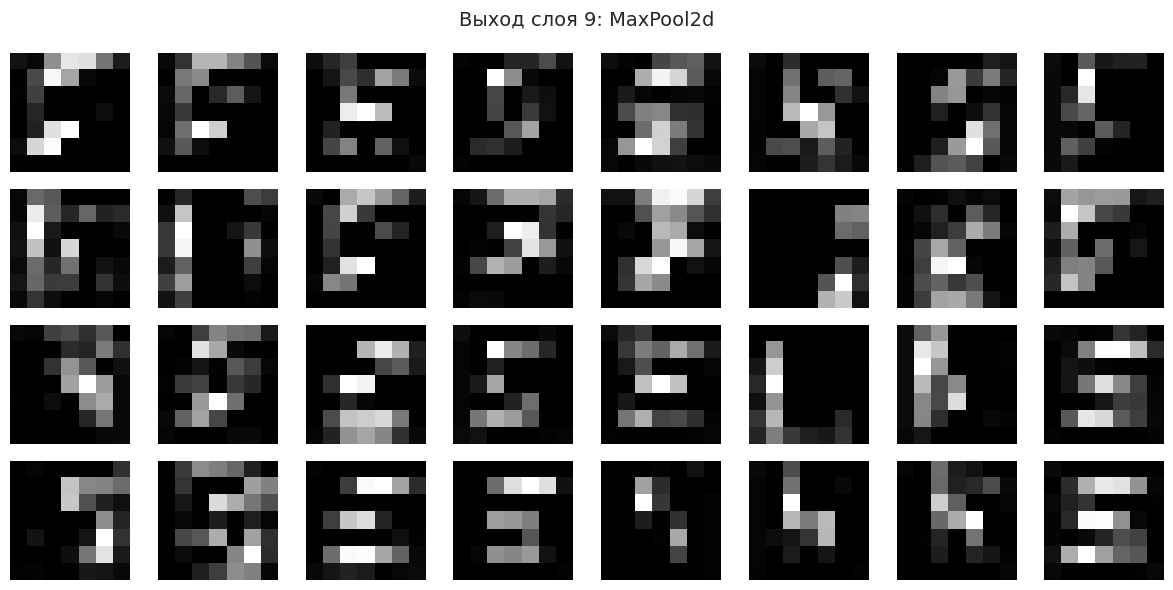

In [35]:
# Показываем 32 карты признаков для каждого слоя
for layer_name, (layer, tensor) in zip(layer_names, outputs):
    c = tensor.shape[1]

    fig, axes = plt.subplots(4, 8, figsize=(12, 6))
    fig.suptitle(f"Выход слоя {layer_name}", fontsize=14)

    for i, ax in enumerate(axes.flat):
        if i < c:
            ax.imshow(tensor[0, i], cmap="gray")
            ax.axis("off")
        else:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

### Анализ выходов сверточных слоев

На изображениях показаны карты признаков, получаемые после прохождения изображения через последовательные слои сети.

На ранних слоях карты признаков сохраняют структуру исходного изображения: отчётливо видны контуры цифры, отдельные линии и штрихи. Разные каналы могут выделять вертикальные или наклонные элементы.

После применения функции активации ReLU часть значений обнуляется, и карты становятся более разреженными. Это означает, что сохраняются только наиболее значимые активации.

После слоев MaxPool уменьшается размер изображения, но при этом сохраняются основные признаки. Это позволяет сети уменьшать размерность данных и одновременно концентрироваться на наиболее важных характеристиках.

На более глубоких слоях карты признаков становятся менее похожими на исходное изображение. Вместо целой цифры видны отдельные области, соответствующие значимым частям изображения.

Таким образом, сеть последовательно преобразует изображение от выделения простых признаков (линии, границы) к более сложным структурам, используемым для классификации.

Какие выводы можно сделать о том, как работает ваша сверточная сеть?

### Вывод о работе сверточной сети

Сверточная сеть обучается иерархии признаков. На первых слоях нейроны реагируют на простые локальные паттерны — линии, границы, отдельные пиксели. На последующих слоях эти признаки комбинируются в более сложные структуры.

С увеличением глубины слоя уменьшается сходство с исходным изображением, но усиливается выделение значимых частей. Глубокие слои реагируют не на всё изображение целиком, а на его ключевые элементы.

Это означает, что сеть работает последовательно от простых элементов к сложным представлениям, которые используются для принятия решения о классе.

Визуализируйте, какие объекты, подаваемые на вход нейросети, в наибольшей степени активируют нейроны в сверточных слоях. Для этого оптимизируйте изображение, чтобы максимизировать выход нейрона.

Ниже представлен шаблон функции, которая находит изображение, максимально усиливающее реакцию нейрона. Пример можно посмотреть в <a href="https://thetahat.ru/files/ad/main/7/CV_complex_no_pause.pdf" target="_blank">презентации</a> с занятия.

In [36]:
# При реализации запрещено пользоваться ИИ-инструментами.

def visualize_filter(
    model: nn.Module,
    layer_index: int,
    target_kernel: int,
    learning_rate: float = 1,
    steps: int = 10_000,
    image_size: int = 28,
    device: Union[str, torch.device] = "cpu",
) -> torch.Tensor:
    """Визуализирует фильтр сверточного слоя нейронной сети путем оптимизации
    входного изображения, которое максимизирует активацию заданного фильтра.

    Параметры:
        model (nn.Module): Модель нейронной сети, содержащая целевой сверточный слой.
        layer_index (int): Индекс целевого сверточного слоя в модели (по порядку в model.children()).
        target_kernel (int): Индекс фильтра в целевом слое для визуализации.
        learning_rate (float, optional): Скорость обучения для оптимизатора. По умолчанию 1.
        steps (int, optional): Количество шагов оптимизации. По умолчанию 10000.
        image_size (int, optional): Размер стороны квадратного входного изображения. По умолчанию 28.
        device (str|torch.device, optional): Устройство для вычислений ('cpu' или 'cuda'). По умолчанию "cpu".

    Возвращает:
        torch.Tensor: Оптимизированное изображение (тензор формы [1, C, H, W]),
                      которое максимизирует активацию целевого фильтра.
    """

    model.eval().to(device)  # Переводим модель в режим оценки

    # Инициализируем изображение случайным шумом
    input_img = torch.randn(1, 1, image_size, image_size, requires_grad=True, device=device)
    # Обратите внимание, что в данном случае мы оптимизируем не модель, а входную картинку
    optimizer = optim.SGD([input_img], lr=learning_rate)

    layers = list(model.children())

    # Функция потерь: максимизируем активацию нужного ядра свертки
    for step in range(steps):
        optimizer.zero_grad()

        current = input_img
        for i, layer in enumerate(layers):
            current = layer(current)
            if i == layer_index:
                break

        # Пропускаем изображение через модель
        output = current  # Выход заданного сверточного слоя
        loss = -output[0, target_kernel].mean()  # Минимизируемая функция

        # Обратное распространение
        loss.backward()
        optimizer.step()

        with torch.no_grad():
          # Нормализуем для стабильности
          # Ограничиваем значения пикселей в разумных пределах
          input_img.data = torch.clamp(input_img.data, -1, 1)
          if step % 100 == 0 and step > 0:
            mean = input_img.data.mean()
            std = input_img.data.std() + 1e-8
            input_img.data = (input_img.data - mean) / std * 0.1

        # Логируем лосс
        if step % 500 == 0:
            print(f"Step {step}/{steps}, Loss: {loss.item():.4f}")

    # Преобразуем оптимизированное изображение
    img = input_img.detach().cpu().squeeze().numpy()

    return img

In [37]:
# Находим индексы всех сверточных слоев в deep_model
conv_layer_indices = []
for i, layer in enumerate(deep_model):
    if isinstance(layer, nn.Conv2d):
        conv_layer_indices.append(i)

print("Индексы свёрточных слоёв:", conv_layer_indices)

Индексы свёрточных слоёв: [0, 2, 5, 7]


In [41]:
filter_results = {}

for layer_idx in conv_layer_indices:
    filter_results[layer_idx] = {}
    for kernel_id in range(32):
        print(f"  Визуализация фильтра {kernel_id} слоя {layer_idx}:")
        img = visualize_filter(
            model=deep_model,
            layer_index=layer_idx,
            target_kernel=kernel_id,
            learning_rate=0.1,
            steps=5000,
            image_size=28,
            device=device
        )
        filter_results[layer_idx][kernel_id] = img

  Визуализация фильтра 0 слоя 0:
Step 0/5000, Loss: -0.0489
Step 500/5000, Loss: -0.0601
Step 1000/5000, Loss: -0.0615
Step 1500/5000, Loss: -0.0629
Step 2000/5000, Loss: -0.0642
Step 2500/5000, Loss: -0.0654
Step 3000/5000, Loss: -0.0666
Step 3500/5000, Loss: -0.0677
Step 4000/5000, Loss: -0.0686
Step 4500/5000, Loss: -0.0695
  Визуализация фильтра 1 слоя 0:
Step 0/5000, Loss: -0.0470
Step 500/5000, Loss: -0.0572
Step 1000/5000, Loss: -0.0576
Step 1500/5000, Loss: -0.0581
Step 2000/5000, Loss: -0.0585
Step 2500/5000, Loss: -0.0588
Step 3000/5000, Loss: -0.0592
Step 3500/5000, Loss: -0.0596
Step 4000/5000, Loss: -0.0599
Step 4500/5000, Loss: -0.0603
  Визуализация фильтра 2 слоя 0:
Step 0/5000, Loss: -0.2034
Step 500/5000, Loss: -0.1822
Step 1000/5000, Loss: -0.1896
Step 1500/5000, Loss: -0.1962
Step 2000/5000, Loss: -0.2017
Step 2500/5000, Loss: -0.2060
Step 3000/5000, Loss: -0.2091
Step 3500/5000, Loss: -0.2113
Step 4000/5000, Loss: -0.2129
Step 4500/5000, Loss: -0.2139
  Визуализаци

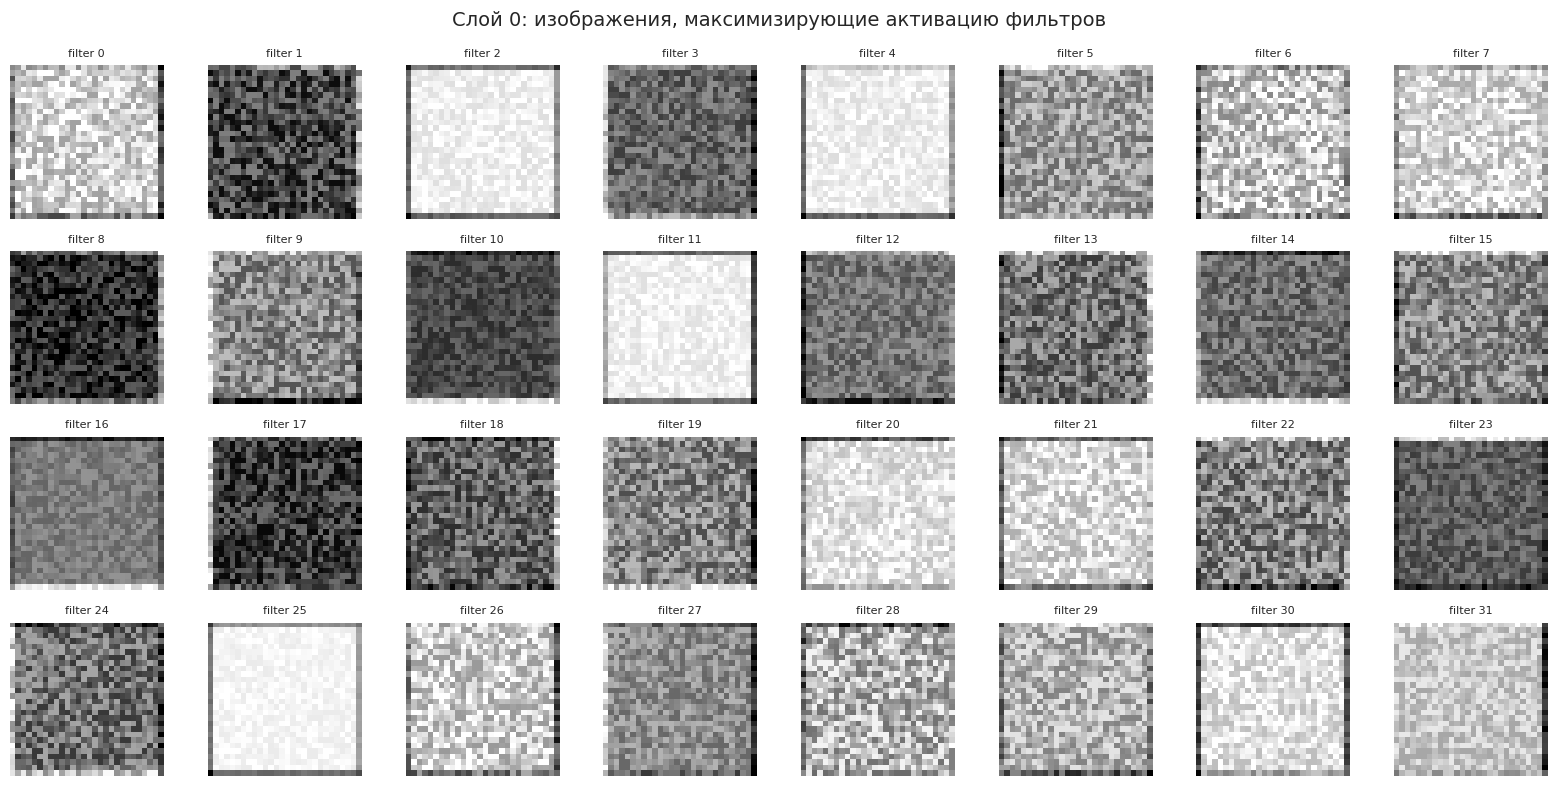

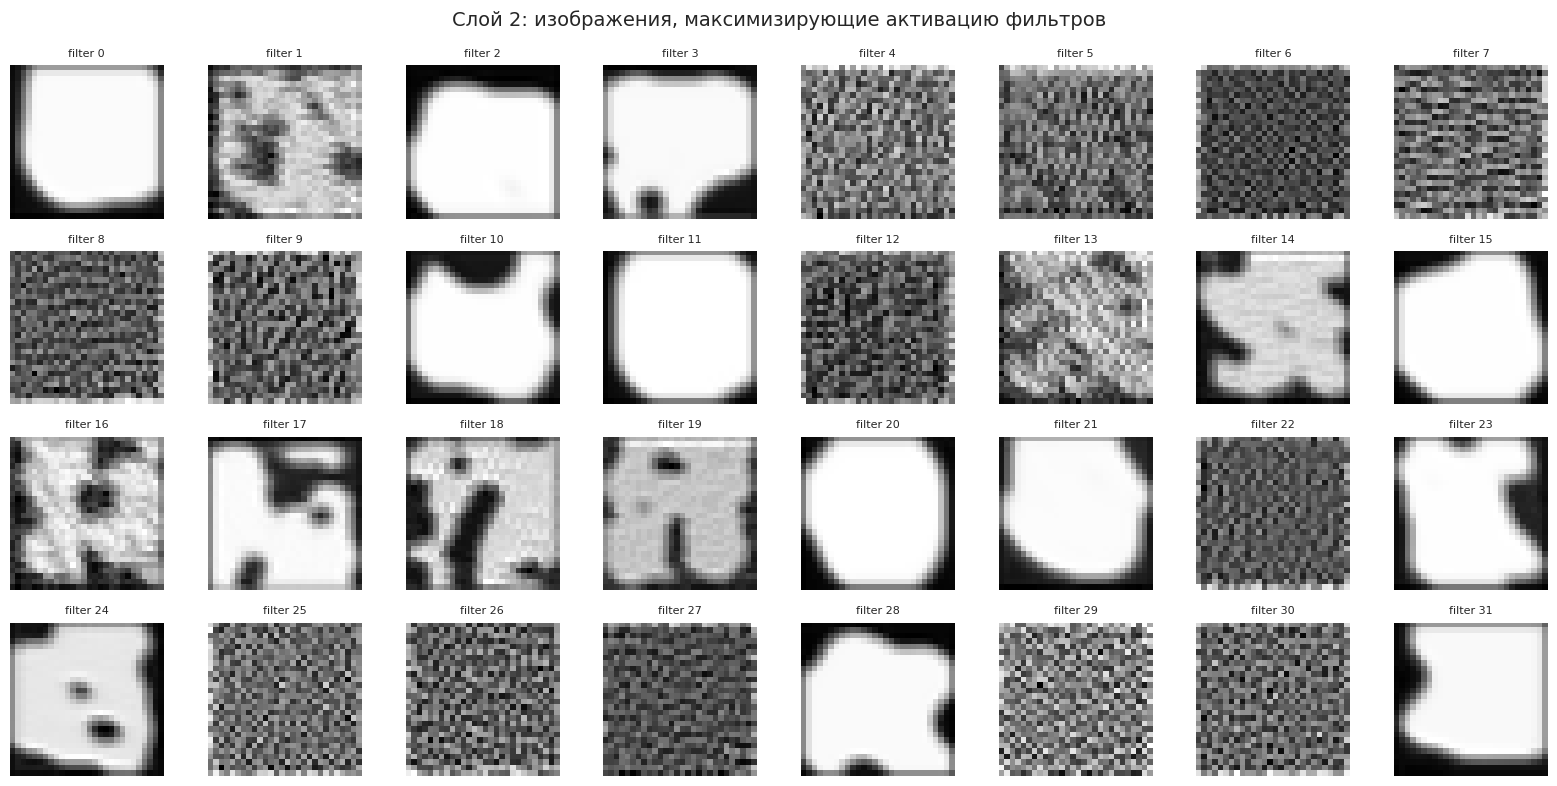

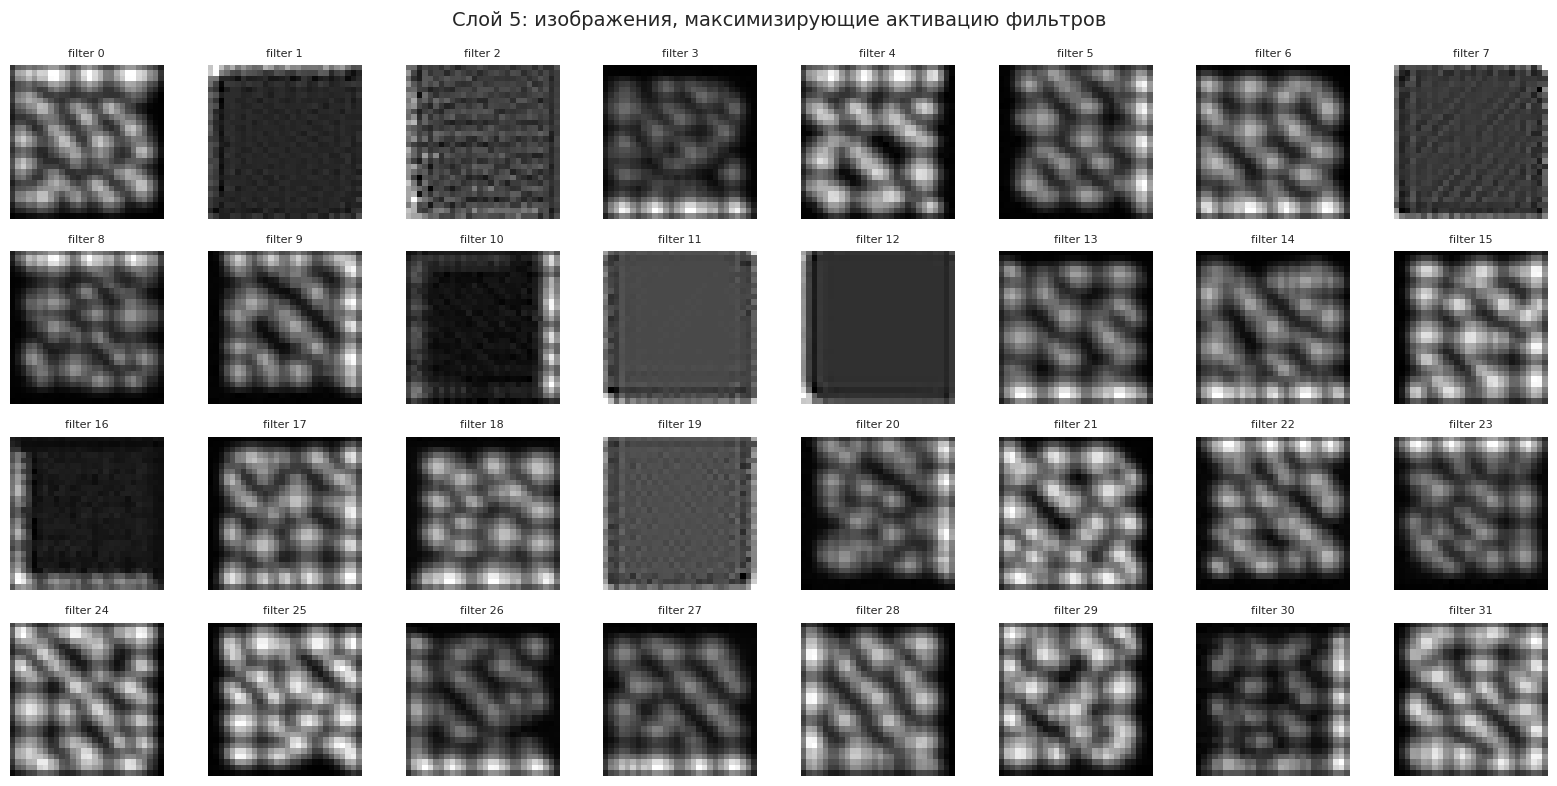

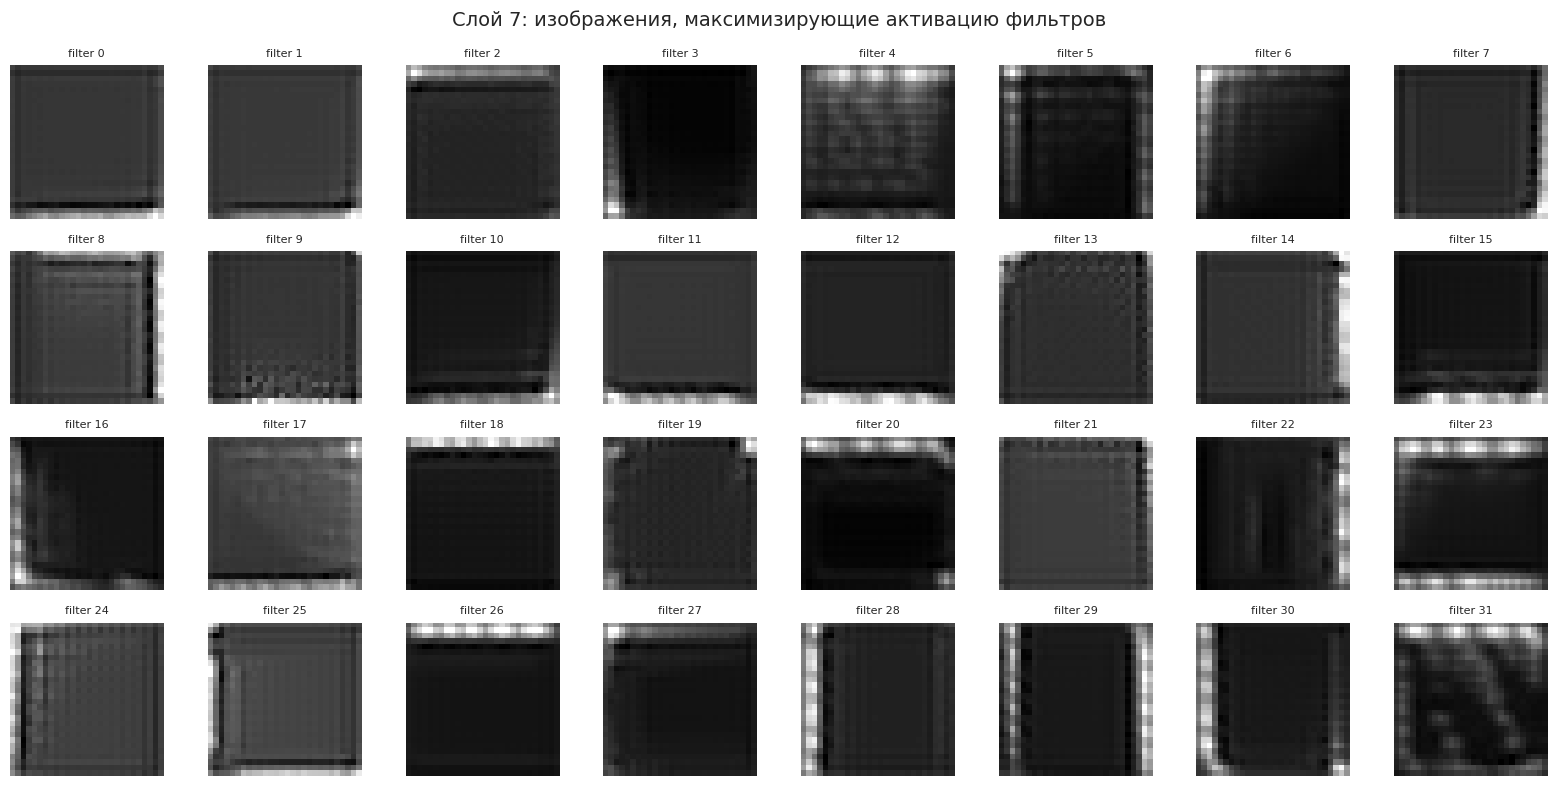

In [42]:
# Визуализируем фильтры из каждого сверточного слоя
for layer_idx in conv_layer_indices:
    fig, axes = plt.subplots(4, 8, figsize=(16, 8))
    fig.suptitle(f"Слой {layer_idx}: изображения, максимизирующие активацию фильтров", fontsize=14)

    for kernel_id, ax in enumerate(axes.flat):
        ax.imshow(filter_results[layer_idx][kernel_id], cmap="gray")
        ax.set_title(f"filter {kernel_id}", fontsize=8)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

### Вывод по визуализации фильтров на разных слоях

На изображениях показаны входные изображения, которые максимизируют активацию отдельных фильтров на разных сверточных слоях (`0`, `2`, `5`, `7`).

На первом слое (индекс 0) изображения представляют собой простые структуры: отдельные точки, разреженные паттерны. Это означает, что нейроны реагируют на базовые локальные признаки.

На промежуточных слоях (индексы 2 и 5) появляются более выраженные структуры: повторяющиеся узоры, линии, направленные текстуры и комбинации пикселей. Это говорит о том, что нейроны начинают реагировать на более сложные признаки, сформированные из комбинаций базовых элементов.

На более глубоких слоях (индекс 7) изображения становятся ещё более структурированными: видны крупные области активации, границы и формы. При этом отдельные фильтры могут давать похожие изображения, что означает специализацию нейронов на определённых типах признаков.

Таким образом, с увеличением глубины слоя способность нейрона воспринимать признаки становится более сложной и абстрактной: от простых локальных паттернов к более сложным и обобщённым структурам.

Сделайте выводы о том, как с глубиной слоя меняется способность нейрона видеть различные паттерны на изображении.

**Ответ:**

С увеличением глубины сверточной сети нейроны переходят от выделения простых локальных признаков к более сложным и абстрактным структурам. Это позволяет модели эффективно извлекать информацию из изображения и достигать высокой точности классификации.

---
### Задача 3. Перенос стиля

*Данную задачу, возможно, проще сделать в Google Colab.*

В данной задаче вы потренируетесь в работе с картинками и составлением промптов. Используя код с <a href="https://thetahat.ru/courses/ad/main/7/cv_complex_examples" target="_blank">семинара</a>, проведите перенос стиля на хотя бы 4 своих примерах.

> Заметьте, что в примерах с семинара в качестве картинок стиля и контента использовались картинки среднего разрешения. Если возникают проблемы, например:
> * оптимизация останавливается на 0-й эпохе и не создает картинку;
> * loss в какой-то момент стал nan;
> * нехватка RAM;
>
> то либо уменьшите разрешение ваших картинок, либо попробуйте картинку полегче.

In [60]:
uploaded = files.upload()
with zipfile.ZipFile("Neural-Style-Transfer.zip", "r") as z:
    z.extractall("/content/")

os.chdir("/content/Neural-Style-Transfer")
print(os.listdir("."))

Saving Neural-Style-Transfer.zip to Neural-Style-Transfer.zip
['requirements.txt', 'data', 'Neural-Style-Transfer.zip', 'Neural-Style-Transfer', 'models', '.git', 'NST.py', 'README.md', 'LICENSE', '__pycache__']


In [61]:
from NST import *

Using VGG19 in the optimization procedure.
L-BFGS | iteration: 000, total loss=3446675865600.0000, content_loss=      0.0000, style loss=3446668560000.0000, tv loss=7292746.0000
L-BFGS | iteration: 001, total loss=3446674817024.0000, content_loss=      0.0011, style loss=3446667360000.0000, tv loss=7292746.0000
L-BFGS | iteration: 002, total loss=3446669049856.0000, content_loss=      0.0294, style loss=3446661600000.0000, tv loss=7292751.0000
L-BFGS | iteration: 003, total loss=3446660661248.0000, content_loss=      0.1463, style loss=3446653200000.0000, tv loss=7292758.5000
L-BFGS | iteration: 004, total loss=3446592241664.0000, content_loss=      4.3781, style loss=3446584800000.0000, tv loss=7292813.0000
L-BFGS | iteration: 005, total loss=3446215278592.0000, content_loss=    130.4031, style loss=3446208000000.0000, tv loss=7293113.0000
L-BFGS | iteration: 006, total loss=3442660343808.0000, content_loss=   9228.7153, style loss=3442652880000.0000, tv loss=7296008.0000
L-BFGS | ite

In [62]:
def run_neural_style_transfer(content_image="c1.jpg", style_image="s1.jpg"):
    PATH = ""
    default_resource_dir = os.path.join(PATH, "data")
    content_images_dir = os.path.join(default_resource_dir, "content-images")
    style_images_dir = os.path.join(default_resource_dir, "style-images")
    output_img_dir = os.path.join(default_resource_dir, "output-images")
    img_format = (4, ".jpg")

    optimization_config = {
        "content_img_name": content_image,
        "style_img_name": style_image,
        "height": 400,
        "content_weight": 100000.0,
        "style_weight": 30000.0,
        "tv_weight": 1.0,
    }
    optimization_config["content_images_dir"] = content_images_dir
    optimization_config["style_images_dir"] = style_images_dir
    optimization_config["output_img_dir"] = output_img_dir
    optimization_config["img_format"] = img_format

    results_path = neural_style_transfer(optimization_config)
    return results_path


def visualize_style_transfer(content_image, style_image, results_path):
    if len(os.listdir(results_path)) == 0:
        return

    plt.figure(figsize=(13, 3))
    folders = [
        "content-images/",
        "output-images/" + Path(results_path).name + "/",
        "style-images/",
    ]
    combined_image = Path(content_image).stem + "_" + Path(style_image).stem + ".jpg"
    files = [content_image, combined_image, style_image]
    titles = ["Контент", "Результат", "Стиль"]

    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(plt.imread("data/" + folders[i] + files[i]))
        plt.title(titles[i])
        plt.xticks([])
        plt.yticks([])

In [63]:
print("Картинки контента:")
print(os.listdir("data/content-images/"))

print("\nКартинки стиля:")
print(os.listdir("data/style-images/"))

Картинки контента:
['c2.jpg', 'c5.jpg', 'c3.jpg', 'c6.jpg', 'c1.jpg', 'c4.jpg']

Картинки стиля:
['s4.jpg', 's5.jpg', 's6.jpg', 's2.jpg', 's3.jpg', 's1.jpg']


In [64]:
my_pairs = [
    ("c1.jpg", "s5.jpg"),
    ("c2.jpg", "s4.jpg"),
    ("c4.jpg", "s2.jpg"),
    ("c5.jpg", "s1.jpg"),
]

my_result_paths = []

for content_image, style_image in my_pairs:
    print(f"\nЗапуск: {content_image} + {style_image}")
    results_path = run_neural_style_transfer(content_image, style_image)
    my_result_paths.append(results_path)


Запуск: c1.jpg + s5.jpg
Using VGG19 in the optimization procedure.
L-BFGS | iteration: 000, total loss=337398792192.0000, content_loss=      0.0000, style loss=337391490000.0000, tv loss=7292746.0000
L-BFGS | iteration: 001, total loss=337398431744.0000, content_loss=      0.0020, style loss=337391130000.0000, tv loss=7292746.0000
L-BFGS | iteration: 002, total loss=337396400128.0000, content_loss=      0.0581, style loss=337389090000.0000, tv loss=7292748.5000
L-BFGS | iteration: 003, total loss=337393123328.0000, content_loss=      0.3264, style loss=337385820000.0000, tv loss=7292752.0000
L-BFGS | iteration: 004, total loss=337367597056.0000, content_loss=      9.8924, style loss=337360290000.0000, tv loss=7292781.0000
L-BFGS | iteration: 005, total loss=337226956800.0000, content_loss=    300.1675, style loss=337219650000.0000, tv loss=7292938.5000
L-BFGS | iteration: 006, total loss=335695675392.0000, content_loss=  30061.9364, style loss=335688330000.0000, tv loss=7294674.0000
L

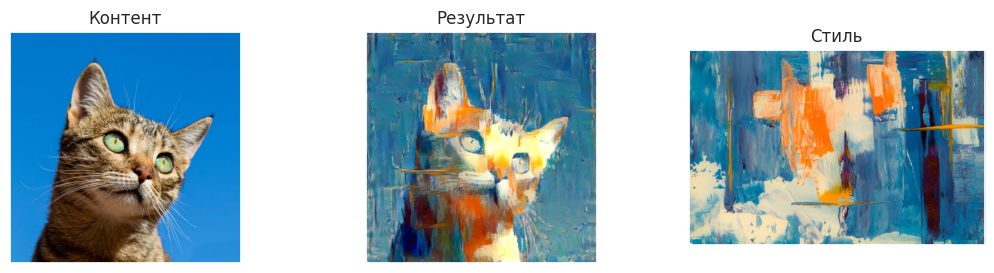

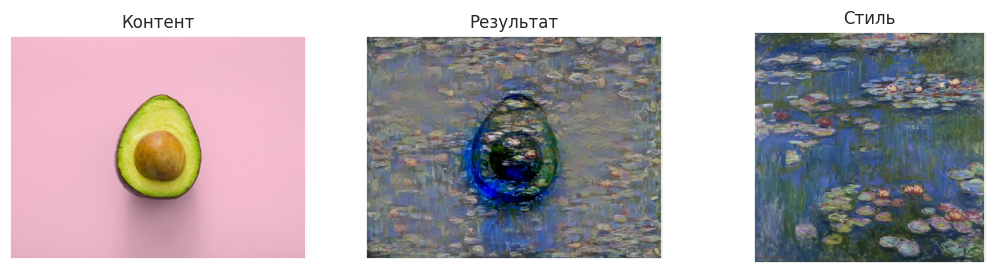

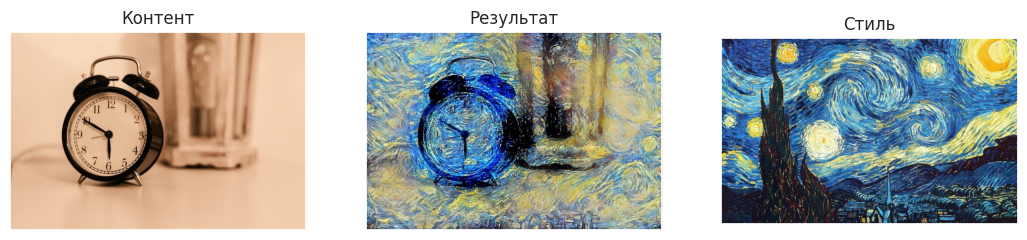

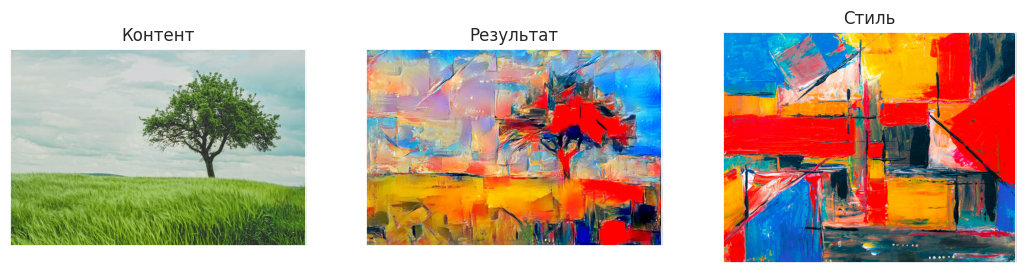

In [65]:
for (content_image, style_image), results_path in zip(my_pairs, my_result_paths):
    visualize_style_transfer(content_image, style_image, results_path)
    plt.show()

Для тех же пар изображений контест-стиль попытайтесь сгенерировать картинку с таким контекстом и стилем с помощью диффузионной модели, рассмотренной на семинаре, задав нужный промпт.

In [66]:
pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sdxl-turbo",
    torch_dtype=torch.float16,
    variant="fp16"
).to("cuda")

model_index.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]


Пара 1: c1.jpg + s5.jpg
Промпт: a close-up portrait of a cat, abstract painting, blue and orange brush strokes, textured canvas, artistic


  0%|          | 0/1 [00:00<?, ?it/s]

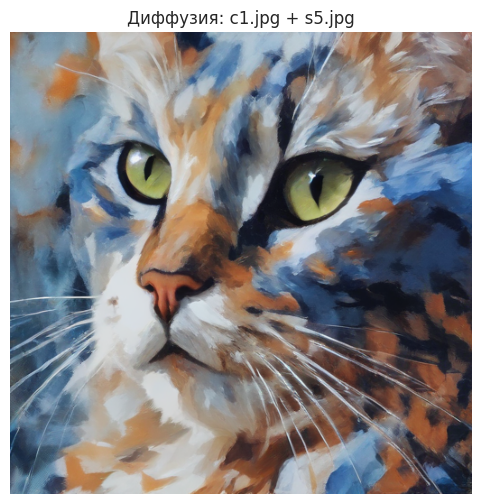


Пара 2: c2.jpg + s4.jpg
Промпт: a half avocado on a pink background, in the style of Claude Monet, impressionist painting, water lilies color palette, soft brush strokes


  0%|          | 0/1 [00:00<?, ?it/s]

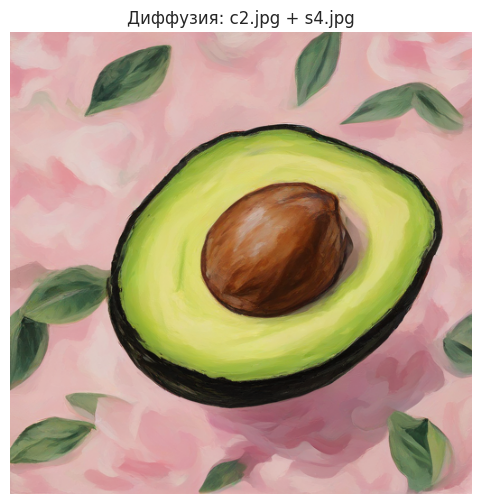


Пара 3: c4.jpg + s2.jpg
Промпт: a vintage alarm clock on a table, in the style of Vincent van Gogh, Starry Night, swirling brush strokes, oil painting


  0%|          | 0/1 [00:00<?, ?it/s]

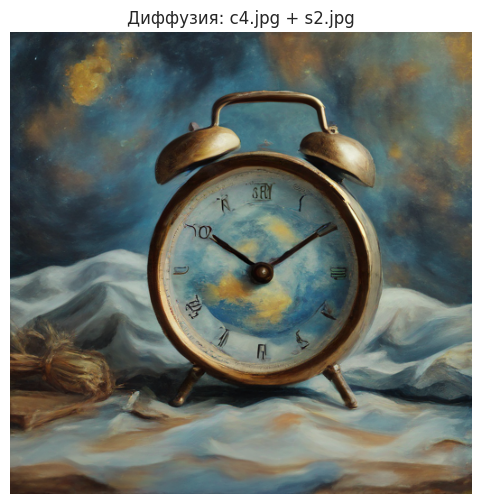


Пара 4: c5.jpg + s1.jpg
Промпт: a lonely tree in a green field under the sky, abstract painting, bold red yellow and blue brush strokes, highly textured


  0%|          | 0/1 [00:00<?, ?it/s]

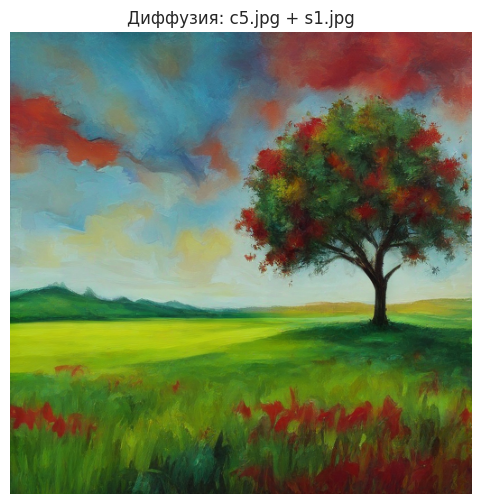

In [74]:
my_pairs = [
    ("c1.jpg", "s5.jpg"),
    ("c2.jpg", "s4.jpg"),
    ("c4.jpg", "s2.jpg"),
    ("c5.jpg", "s1.jpg"),
]

prompts = [
    "a close-up portrait of a cat, abstract painting, blue and orange brush strokes, textured canvas, artistic",
    "a half avocado on a pink background, in the style of Claude Monet, impressionist painting, water lilies color palette, soft brush strokes",
    "a vintage alarm clock on a table, in the style of Vincent van Gogh, Starry Night, swirling brush strokes, oil painting",
    "a lonely tree in a green field under the sky, abstract painting, bold red yellow and blue brush strokes, highly textured"
]

for i, (content_image, style_image) in enumerate(my_pairs):
    prompt = prompts[i]
    print(f"\nПара {i+1}: {content_image} + {style_image}")
    print(f"Промпт: {prompt}")

    image = pipe(
        prompt=prompt,
        num_inference_steps=1,
        guidance_scale=0.0
    ).images[0]

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(f"Диффузия: {content_image} + {style_image}")
    plt.axis("off")
    plt.show()


**Вывод:** с увеличением сложности сцены диффузионная модель всё больше отклоняется от исходного изображения контента. При этом стиль передаётся достаточно уверенно, но композиция становится менее точной и более генеративной.

**Вывод:**

В данной задаче были рассмотрены два подхода к генерации изображений: нейросетевой перенос стиля и генерация изображений с помощью диффузионной модели.

Метод переноса стиля показал, что он эффективно объединяет содержание одного изображения и стиль другого. В полученных результатах хорошо сохраняется структура исходной картинки, при этом изменяются текстуры, цвета и художественная манера. Наиболее удачные результаты получаются в случаях, когда объекты имеют простую и чёткую форму.

Диффузионная модель работает по другому принципу: она не использует исходное изображение напрямую, а генерирует новое изображение на основе текстового описания. В результате удаётся передать общий контекст сцены и стиль, но композиция и детали могут отличаться от исходного изображения.

Сравнение показало, что перенос стиля лучше подходит для задач, где важно сохранить конкретное изображение, а диффузионные модели — для генерации новых изображений по заданной идее и стилю.

Таким образом, оба подхода решают схожие задачи, но делают это разными способами: один — через преобразование изображения, другой — через генерацию нового.

---
© 2026 команда <a href="https://thetahat.ru/">ThetaHat</a> для ВвАД